In [ ]:
import sys
import random
from pathlib import Path

import numpy as np
import torch

ROOT = Path("..") if Path.cwd().name in ("problem1", "problem2") else Path(".")

PROJECT_DIR = ROOT
PROJECT_ROOT = ROOT
PROBLEM1_DIR = ROOT / "problem1"
PROBLEM2_DIR = ROOT / "problem2"
P1_FIGURES_DIR = PROBLEM1_DIR / "figures"
P2_FIGURES_DIR = PROBLEM2_DIR / "figures"

DATA_DIR = ROOT / "data"                  # datasets (excluded from the zip)
CHECKPOINT_DIR = ROOT / "checkpoints"     # weights  (excluded from the zip)

# Problem 1 checkpoints
MODEL_DIR = CHECKPOINT_DIR / "problem1" / "har"
ADDING_MODEL_DIR = CHECKPOINT_DIR / "problem1" / "adding"
ABLATION_DIR = CHECKPOINT_DIR / "problem1" / "hidden_size_ablation"
FORGET_DIR = CHECKPOINT_DIR / "problem1" / "forget_gate_ablation"

# Problem 2 checkpoints
P2_MODELS_DIR = CHECKPOINT_DIR / "problem2"
P2_MODEL_DIR = P2_MODELS_DIR

for folder in [PROBLEM1_DIR, PROBLEM2_DIR, P1_FIGURES_DIR, P2_FIGURES_DIR,
               DATA_DIR, MODEL_DIR, ADDING_MODEL_DIR, ABLATION_DIR,
               FORGET_DIR, P2_MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Working directory :", Path.cwd())
print("Project root      :", ROOT)
print("Problem 1 folder  :", PROBLEM1_DIR)
print("Problem 2 folder  :", PROBLEM2_DIR)
print("Data folder       :", DATA_DIR)
print("Checkpoint folder :", CHECKPOINT_DIR)


Working directory : <notebook folder>/problem2
Project root      : ..
Problem 1 folder  : ../problem1
Problem 2 folder  : ../problem2
Data folder       : ../data
Checkpoint folder : ../checkpoints


## Step 2 — Scaled Dot-Product Attention

In [ ]:
import torch
import torch.nn.functional as F
import math

def scaled_dot_product_attention(Q, K, V, mask=None, causal=False):
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)

    if causal:
        seq_len_q = Q.size(-2)
        seq_len_k = K.size(-2)
        causal_mask = torch.tril(
            torch.ones(seq_len_q, seq_len_k, device=Q.device, dtype=torch.bool)
        )
        scores = scores.masked_fill(~causal_mask, float("-inf"))

    if mask is not None:
        if mask.dtype == torch.bool:
            scores = scores.masked_fill(~mask, float("-inf"))
        else:
            scores = scores + mask

    attention_weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(attention_weights, V)

    return output, attention_weights


torch.manual_seed(42)

Q = torch.randn(2, 4, 6, 8)
K = torch.randn(2, 4, 6, 8)
V = torch.randn(2, 4, 6, 8)

output, weights = scaled_dot_product_attention(Q, K, V)

assert output.shape == (2, 4, 6, 8)
assert weights.shape == (2, 4, 6, 6)
assert torch.allclose(
    weights.sum(dim=-1),
    torch.ones_like(weights.sum(dim=-1)),
    atol=1e-5
)

reference_output = F.scaled_dot_product_attention(Q, K, V)

assert torch.allclose(output, reference_output, atol=1e-5)

print("Basic attention test passed.")
print("Output shape:", output.shape)
print("Attention weights shape:", weights.shape)
print("Maximum difference from PyTorch:", (output - reference_output).abs().max().item())

causal_output, causal_weights = scaled_dot_product_attention(
    Q, K, V, causal=True
)

future_attention = torch.triu(
    causal_weights,
    diagonal=1
)

assert torch.allclose(
    future_attention,
    torch.zeros_like(future_attention),
    atol=1e-7
)

causal_reference = F.scaled_dot_product_attention(
    Q, K, V, is_causal=True
)

assert torch.allclose(causal_output, causal_reference, atol=1e-5)

print("\nCausal attention test passed.")
print("Maximum future attention:", future_attention.max().item())
print("Maximum causal output difference:", (causal_output - causal_reference).abs().max().item())

print("\nSTEP 2 COMPLETED SUCCESSFULLY.")

Basic attention test passed.
Output shape: torch.Size([2, 4, 6, 8])
Attention weights shape: torch.Size([2, 4, 6, 6])
Maximum difference from PyTorch: 3.5762786865234375e-07

Causal attention test passed.
Maximum future attention: 0.0
Maximum causal output difference: 2.384185791015625e-07

STEP 2 COMPLETED SUCCESSFULLY.


### Step 2B — Three-token hand-checkable attention example

The assignment does not provide a specific numerical example, so this illustrative example shows scaled dot-product attention on three tokens. The test sits directly after the function it tests and passes Q, K, V through `scaled_dot_product_attention()` above (nothing is recomputed by hand in code).

Consider the query (Q), key (K) and value (V) vectors:

**Q = K = [1, 0, -1]ᵀ**, **V = [1, 2, 4]ᵀ**, with key dimension **dₖ = 1**.

**Step 1: attention scores.** S = (Q × Kᵀ) / √dₖ and √1 = 1, so S = Q × Kᵀ:

```text
S = |  1   0  -1 |
    |  0   0   0 |
    | -1   0   1 |
```

**Step 2: row-wise softmax.** A = softmax(S):

```text
A ≈ | 0.665241  0.244728  0.090031 |
    | 0.333333  0.333333  0.333333 |
    | 0.090031  0.244728  0.665241 |
```

For example, row 1 is [e¹, e⁰, e⁻¹] / (e¹ + e⁰ + e⁻¹) = [2.7183, 1, 0.3679] / 4.0861.

**Step 3: output.** O = A × V:

```text
O ≈ | 1.514819 |
    | 2.333333 |
    | 3.240453 |
```

For example, O₁ = 0.665241·1 + 0.244728·2 + 0.090031·4 = 1.514819 and O₂ = (1 + 2 + 4) / 3 = 2.333333.

The next cell checks the hand-computed weights and output against the code.

In [ ]:
# Three-token hand-checkable example (Q = K = [1, 0, -1], V = [1, 2, 4], d_k = 1)
# Shapes: Q, K, V are (batch=1, tokens=3, d=1); weights are (1, 3, 3); output is (1, 3, 1).
Q_example = torch.tensor([[[1.0], [0.0], [-1.0]]])
K_example = torch.tensor([[[1.0], [0.0], [-1.0]]])
V_example = torch.tensor([[[1.0], [2.0], [4.0]]])

# Run the example through the scaled_dot_product_attention() defined above
output_example, weights_example = scaled_dot_product_attention(
    Q_example, K_example, V_example
)

# Values computed by hand (see the markdown above)
expected_weights = torch.tensor([
    [0.665241, 0.244728, 0.090031],
    [0.333333, 0.333333, 0.333333],
    [0.090031, 0.244728, 0.665241],
])
expected_output = torch.tensor([[[1.514819], [2.333333], [3.240453]]])

assert weights_example.shape == (1, 3, 3)
assert output_example.shape == (1, 3, 1)
assert torch.allclose(weights_example[0], expected_weights, atol=1e-5)
assert torch.allclose(output_example, expected_output, atol=1e-5)
assert torch.allclose(weights_example.sum(dim=-1), torch.ones(1, 3), atol=1e-6)

# The library function must agree as well
assert torch.allclose(
    output_example,
    F.scaled_dot_product_attention(Q_example, K_example, V_example),
    atol=1e-5
)

print("THREE-TOKEN HAND-CHECKABLE EXAMPLE PASSED")
print("Output shape:", tuple(output_example.shape))
print("Attention weights:")
print(weights_example[0])
print("Attention output:", output_example.flatten().tolist())


## Step 3 — Multi-Head Attention

In [ ]:
class MultiHeadAttention(torch.nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads.")

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.WQ = torch.nn.Linear(d_model, d_model)
        self.WK = torch.nn.Linear(d_model, d_model)
        self.WV = torch.nn.Linear(d_model, d_model)
        self.WO = torch.nn.Linear(d_model, d_model)

    def split_heads(self, x):
        batch_size, seq_len, _ = x.shape
        x = x.reshape(batch_size, seq_len, self.num_heads, self.head_dim)
        return x.transpose(1, 2)

    def forward(self, query, key, value, mask=None, causal=False):
        Q = self.split_heads(self.WQ(query))
        K = self.split_heads(self.WK(key))
        V = self.split_heads(self.WV(value))

        attention_output, attention_weights = scaled_dot_product_attention(
            Q, K, V, mask=mask, causal=causal
        )

        attention_output = attention_output.transpose(1, 2).contiguous()
        batch_size, seq_len, _, _ = attention_output.shape

        attention_output = attention_output.reshape(
            batch_size, seq_len, self.d_model
        )

        output = self.WO(attention_output)

        return output, attention_weights


torch.manual_seed(42)

batch_size = 2
seq_len = 10
d_model = 128
num_heads = 4

mha = MultiHeadAttention(d_model, num_heads)

x = torch.randn(batch_size, seq_len, d_model)

output, attention_weights = mha(x, x, x)

assert output.shape == (batch_size, seq_len, d_model)
assert attention_weights.shape == (batch_size, num_heads, seq_len, seq_len)

assert torch.allclose(
    attention_weights.sum(dim=-1),
    torch.ones_like(attention_weights.sum(dim=-1)),
    atol=1e-5
)

Q = mha.split_heads(mha.WQ(x))
K = mha.split_heads(mha.WK(x))
V = mha.split_heads(mha.WV(x))

reference_heads = F.scaled_dot_product_attention(Q, K, V)
reference_heads = reference_heads.transpose(1, 2).contiguous()
reference_heads = reference_heads.reshape(batch_size, seq_len, d_model)
reference_output = mha.WO(reference_heads)

assert torch.allclose(output, reference_output, atol=1e-5)

parameter_count = sum(p.numel() for p in mha.parameters())

print("Multi-Head Attention test passed.")
print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", attention_weights.shape)
print("Number of heads:", num_heads)
print("Head dimension:", mha.head_dim)
print("Trainable parameters:", parameter_count)
print("Maximum difference from PyTorch SDPA reference:",
      (output - reference_output).abs().max().item())
print("\nSTEP 3 COMPLETED SUCCESSFULLY.")

Multi-Head Attention test passed.
Input shape: torch.Size([2, 10, 128])
Output shape: torch.Size([2, 10, 128])
Attention weights shape: torch.Size([2, 4, 10, 10])
Number of heads: 4
Head dimension: 32
Trainable parameters: 66048
Maximum difference from PyTorch SDPA reference: 1.1920928955078125e-07

STEP 3 COMPLETED SUCCESSFULLY.


## Step 4 — Transformer Encoder Components

### Step 4A — Sinusoidal Positional Encoding

In [ ]:
class SinusoidalPositionalEncoding(torch.nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()

        position = torch.arange(max_len).unsqueeze(1).float()
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

### Step 4B — Feed-Forward Network and Encoder Block

In [ ]:
class FeedForwardNetwork(torch.nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()

        self.network = torch.nn.Sequential(
            torch.nn.Linear(d_model, d_ff),
            torch.nn.ReLU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(d_ff, d_model)
        )

    def forward(self, x):
        return self.network(x)


class TransformerEncoderBlock(torch.nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        self.norm1 = torch.nn.LayerNorm(d_model)
        self.attention = MultiHeadAttention(d_model, num_heads)
        self.norm2 = torch.nn.LayerNorm(d_model)
        self.feed_forward = FeedForwardNetwork(d_model, d_ff, dropout)
        self.dropout = torch.nn.Dropout(dropout)

    def forward(self, x, mask=None):
        attention_output, attention_weights = self.attention(
            self.norm1(x),
            self.norm1(x),
            self.norm1(x),
            mask=mask
        )

        x = x + self.dropout(attention_output)
        x = x + self.dropout(self.feed_forward(self.norm2(x)))

        return x, attention_weights

### Step 4C — Verification

In [ ]:
torch.manual_seed(42)

d_model = 128
num_heads = 4
d_ff = 4 * d_model
seq_len = 20
batch_size = 2

positional_encoding = SinusoidalPositionalEncoding(
    d_model=d_model,
    max_len=512
)

encoder_block = TransformerEncoderBlock(
    d_model=d_model,
    num_heads=num_heads,
    d_ff=d_ff,
    dropout=0.1
)

x = torch.randn(batch_size, seq_len, d_model)

x_positioned = positional_encoding(x)
output, attention_weights = encoder_block(x_positioned)

assert x_positioned.shape == (batch_size, seq_len, d_model)
assert output.shape == (batch_size, seq_len, d_model)
assert attention_weights.shape == (batch_size, num_heads, seq_len, seq_len)
assert torch.isfinite(output).all()
assert torch.isfinite(attention_weights).all()

expected_parameters = (
    4 * d_model * d_model
    + 2 * d_model * d_ff
)

actual_parameters = sum(
    p.numel() for p in encoder_block.parameters()
)

print("Sinusoidal positional encoding shape:", x_positioned.shape)
print("Encoder output shape:", output.shape)
print("Attention weights shape:", attention_weights.shape)
print("Expected encoder block weight parameters:", expected_parameters)
print("Actual encoder block parameters including biases and LayerNorm:", actual_parameters)
print("All output values finite:", torch.isfinite(output).all().item())
print("\nSTEP 4 COMPLETED SUCCESSFULLY.")

Sinusoidal positional encoding shape: torch.Size([2, 20, 128])
Encoder output shape: torch.Size([2, 20, 128])
Attention weights shape: torch.Size([2, 4, 20, 20])
Expected encoder block weight parameters: 196608
Actual encoder block parameters including biases and LayerNorm: 198272
All output values finite: True

STEP 4 COMPLETED SUCCESSFULLY.


## Step 5 — HAR Transformer Classifier

### Step 5A — Reuse of the Problem 1 HAR data pipeline

In [ ]:
# Problem 2 reuses the Problem 1 HAR pipeline. The next cell repeats it so
# that this notebook also runs on its own:
#   same download URL and data/ folder, subject-wise validation split
#   (np.random.default_rng(seed).choice(train_subjects, 4, replace=False)),
#   and per-channel mean/std computed on the training part only.
print("HAR DATA SOURCE")
print("Problem 2 Task A uses the same HAR data pipeline as Problem 1.")
print("Splits: seeds 13, 309, 2004 | 17 training and 4 validation subjects per seed.")
print("Normalisation: per-channel mean and std from the training part only.")


HAR DATA SOURCE
Problem 2 Task A uses the same HAR data pipeline as Problem 1.
Splits: seeds 13, 309, 2004 | 17 training and 4 validation subjects per seed.
Normalisation: per-channel mean and std from the training part only.


### Step 5B — Load and prepare HAR data in Problem 2

In [ ]:

import urllib.request
import zipfile
import numpy as np
import torch
from pathlib import Path

HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_ZIP = DATA_DIR / "UCI_HAR_Dataset.zip"
HAR_EXTRACT_DIR = DATA_DIR / "UCI_HAR_Dataset"

HAR_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

HAR_DIR = HAR_EXTRACT_DIR / "UCI HAR Dataset"
SIGNALS_DIR = HAR_DIR / "train" / "Inertial Signals"
NESTED_ZIP = HAR_EXTRACT_DIR / "UCI HAR Dataset.zip"

# Download only if the dataset is not already on disk (Problem 1 and
# Problem 2 share the same data/ folder).
if not SIGNALS_DIR.exists():
    if not HAR_ZIP.exists():
        print("Downloading UCI HAR dataset...")
        try:
            urllib.request.urlretrieve(HAR_URL, HAR_ZIP)
        except Exception as error:
            raise RuntimeError(
                "UCI HAR download failed. If the site is blocked, download "
                "the zip manually (instructor mirror) and save it as "
                f"{HAR_ZIP}, then re-run this cell."
            ) from error

    if not NESTED_ZIP.exists():
        with zipfile.ZipFile(HAR_ZIP, "r") as zip_file:
            zip_file.extractall(HAR_EXTRACT_DIR)

    # The archive holds a second zip, 'UCI HAR Dataset.zip': extract it too.
    if not SIGNALS_DIR.exists() and NESTED_ZIP.exists():
        with zipfile.ZipFile(NESTED_ZIP, "r") as zip_file:
            zip_file.extractall(HAR_EXTRACT_DIR)

feature_names = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

def load_har_split(split):
    split_dir = HAR_DIR / split
    signals_dir = split_dir / "Inertial Signals"
    signals = []

    for feature in feature_names:
        file_path = signals_dir / f"{feature}_{split}.txt"
        signal = np.loadtxt(file_path, dtype=np.float32)
        signals.append(signal)

    X = np.stack(signals, axis=2)
    y = np.loadtxt(split_dir / f"y_{split}.txt", dtype=np.int64)
    subjects = np.loadtxt(split_dir / f"subject_{split}.txt", dtype=np.int64)

    return X, y, subjects

X_train_raw, y_train_raw, train_subjects_all = load_har_split("train")
X_test_raw, y_test, test_subjects = load_har_split("test")

train_subject_ids = np.unique(train_subjects_all)
test_subject_ids = np.unique(test_subjects)

VALIDATION_SEEDS = [13, 309, 2004]
validation_splits = {}

for seed in VALIDATION_SEEDS:
    rng = np.random.default_rng(seed)
    validation_subject_ids = rng.choice(train_subject_ids, 4, replace=False)
    training_subject_ids = np.setdiff1d(train_subject_ids, validation_subject_ids)

    train_indices = np.where(np.isin(train_subjects_all, training_subject_ids))[0]
    val_indices = np.where(np.isin(train_subjects_all, validation_subject_ids))[0]

    X_train = X_train_raw[train_indices]
    y_train = y_train_raw[train_indices]
    X_val = X_train_raw[val_indices]
    y_val = y_train_raw[val_indices]

    channel_mean = X_train.mean(axis=(0, 1))
    channel_std = X_train.std(axis=(0, 1))
    channel_std[channel_std == 0] = 1.0

    split = {
        "X_train": (X_train - channel_mean) / channel_std,
        "y_train": y_train - 1,
        "X_val": (X_val - channel_mean) / channel_std,
        "y_val": y_val - 1,
        "X_test": (X_test_raw - channel_mean) / channel_std,
        "y_test": y_test - 1,
        "train_subjects": training_subject_ids,
        "val_subjects": validation_subject_ids,
        "mean": channel_mean,
        "std": channel_std
    }

    validation_splits[seed] = split

    assert len(training_subject_ids) == 17
    assert len(validation_subject_ids) == 4
    assert np.all(np.isfinite(split["X_train"]))
    assert np.all(np.isfinite(split["X_val"]))
    assert np.all(np.isfinite(split["X_test"]))
    assert np.allclose(split["X_train"].mean(axis=(0, 1)), 0, atol=0.01)
    assert np.allclose(split["X_train"].std(axis=(0, 1)), 1, atol=0.01)

print("HAR DATA PREPARATION COMPLETED")
print("Training data:", X_train_raw.shape)
print("Test data:", X_test_raw.shape)
print("Training subjects:", len(train_subject_ids))
print("Test subjects:", len(test_subject_ids))

for seed, split in validation_splits.items():
    print(
        f"Seed {seed} | "
        f"Train: {split['X_train'].shape} | "
        f"Validation: {split['X_val'].shape} | "
        f"Test: {split['X_test'].shape}"
    )

print("All normalization and subject split checks passed.")


HAR DATA PREPARATION COMPLETED
Training data: (7352, 128, 9)
Test data: (2947, 128, 9)
Training subjects: 21
Test subjects: 9
Seed 13 | Train: (5858, 128, 9) | Validation: (1494, 128, 9) | Test: (2947, 128, 9)
Seed 309 | Train: (5988, 128, 9) | Validation: (1364, 128, 9) | Test: (2947, 128, 9)
Seed 2004 | Train: (5880, 128, 9) | Validation: (1472, 128, 9) | Test: (2947, 128, 9)
All normalization and subject split checks passed.


## Step 6 — Build the HAR Transformer classifier

In [ ]:

class HARTransformerClassifier(torch.nn.Module):
    def __init__(
        self,
        input_channels=9,
        sequence_length=128,
        patch_size=8,
        d_model=128,
        num_heads=4,
        num_layers=4,
        d_ff=512,
        num_classes=6,
        dropout=0.1,
        positional_type="sinusoidal"
    ):
        super().__init__()

        if sequence_length % patch_size != 0:
            raise ValueError("Sequence length must be divisible by patch size.")

        self.patch_size = patch_size
        self.num_patches = sequence_length // patch_size
        self.d_model = d_model

        self.patch_projection = torch.nn.Linear(
            patch_size * input_channels, d_model
        )

        self.cls_token = torch.nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

        self.positional_type = positional_type

        if positional_type == "sinusoidal":
            self.positional_encoding = SinusoidalPositionalEncoding(
                d_model, self.num_patches + 1
            )
        elif positional_type == "learned":
            self.position_embedding = torch.nn.Parameter(
                torch.zeros(1, self.num_patches + 1, d_model)
            )
            torch.nn.init.normal_(self.position_embedding, std=0.02)
        elif positional_type == "none":
            self.positional_encoding = None
        else:
            raise ValueError("Unknown positional encoding type.")

        torch.nn.init.normal_(self.cls_token, std=0.02)

        self.dropout = torch.nn.Dropout(dropout)

        self.encoder_layers = torch.nn.ModuleList([
            TransformerEncoderBlock(
                d_model, num_heads, d_ff, dropout
            )
            for _ in range(num_layers)
        ])

        self.final_norm = torch.nn.LayerNorm(d_model)
        self.classifier = torch.nn.Linear(d_model, num_classes)

    def forward(self, x, return_attention=False):
        batch_size, seq_len, channels = x.shape

        if seq_len % self.patch_size != 0:
            raise ValueError("Input sequence length must be divisible by patch size.")

        x = x.reshape(
            batch_size,
            seq_len // self.patch_size,
            self.patch_size * channels
        )

        x = self.patch_projection(x)

        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)

        if self.positional_type == "sinusoidal":
            x = self.positional_encoding(x)
        elif self.positional_type == "learned":
            x = x + self.position_embedding[:, :x.size(1), :]

        x = self.dropout(x)

        attention_maps = []

        for layer in self.encoder_layers:
            x, attention_weights = layer(x)
            attention_maps.append(attention_weights)

        x = self.final_norm(x)
        logits = self.classifier(x[:, 0])

        if return_attention:
            return logits, attention_maps

        return logits


torch.manual_seed(42)

transformer_model = HARTransformerClassifier()

dummy_input = torch.randn(2, 128, 9)
dummy_output, dummy_attention = transformer_model(
    dummy_input, return_attention=True
)

parameter_count = sum(
    parameter.numel()
    for parameter in transformer_model.parameters()
)

assert dummy_output.shape == (2, 6)
assert len(dummy_attention) == 4
assert dummy_attention[0].shape == (2, 4, 17, 17)
assert torch.isfinite(dummy_output).all()

print("HAR Transformer architecture verification passed.")
print("Input shape:", dummy_input.shape)
print("Number of patches:", transformer_model.num_patches)
print("Patch size:", transformer_model.patch_size)
print("CLS token shape:", transformer_model.cls_token.shape)
print("Output shape:", dummy_output.shape)
print("Encoder layers:", len(transformer_model.encoder_layers))
print("Attention shape:", dummy_attention[0].shape)
print("Trainable parameters:", f"{parameter_count:,}")


HAR Transformer architecture verification passed.
Input shape: torch.Size([2, 128, 9])
Number of patches: 16
Patch size: 8
CLS token shape: torch.Size([1, 1, 128])
Output shape: torch.Size([2, 6])
Encoder layers: 4
Attention shape: torch.Size([2, 4, 17, 17])
Trainable parameters: 803,590


## Step 7 — Train and evaluate the HAR Transformer

In [ ]:

import copy
import random
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 0.001

transformer_results = []

for seed in VALIDATION_SEEDS:
    print(f"\nTraining HAR Transformer | Seed {seed}")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    split = validation_splits[seed]

    X_train_tensor = torch.tensor(
        split["X_train"], dtype=torch.float32
    )
    y_train_tensor = torch.tensor(
        split["y_train"], dtype=torch.long
    )
    X_val_tensor = torch.tensor(
        split["X_val"], dtype=torch.float32, device=DEVICE
    )
    y_val_tensor = torch.tensor(
        split["y_val"], dtype=torch.long, device=DEVICE
    )
    X_test_tensor = torch.tensor(
        split["X_test"], dtype=torch.float32, device=DEVICE
    )
    y_test_tensor = torch.tensor(
        split["y_test"], dtype=torch.long, device=DEVICE
    )

    train_dataset = torch.utils.data.TensorDataset(
        X_train_tensor, y_train_tensor
    )
    generator = torch.Generator().manual_seed(seed)

    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    model = HARTransformerClassifier().to(DEVICE)

    parameter_count = sum(
        parameter.numel() for parameter in model.parameters()
    )

    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    best_val_f1 = -1.0
    best_state = None
    epoch_times = []

    for epoch in range(EPOCHS):
        model.train()
        epoch_start = time.perf_counter()
        total_loss = 0.0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_X)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        epoch_times.append(time.perf_counter() - epoch_start)

        model.eval()
        val_predictions = []

        with torch.no_grad():
            for start in range(0, len(X_val_tensor), BATCH_SIZE):
                batch_X = X_val_tensor[start:start + BATCH_SIZE]
                outputs = model(batch_X)
                val_predictions.extend(
                    outputs.argmax(dim=1).cpu().numpy()
                )

        val_f1 = f1_score(
            split["y_val"],
            val_predictions,
            average="macro"
        )

        val_accuracy = accuracy_score(
            split["y_val"],
            val_predictions
        )

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Loss: {total_loss / len(train_dataset):.4f} | "
                f"Validation accuracy: {val_accuracy:.4f} | "
                f"Validation macro-F1: {val_f1:.4f}"
            )

    model.load_state_dict(best_state)
    model.eval()

    test_predictions = []

    with torch.no_grad():
        for start in range(0, len(X_test_tensor), BATCH_SIZE):
            batch_X = X_test_tensor[start:start + BATCH_SIZE]
            outputs = model(batch_X)
            test_predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )

    test_accuracy = accuracy_score(
        split["y_test"], test_predictions
    )
    test_f1 = f1_score(
        split["y_test"], test_predictions, average="macro"
    )

    checkpoint_path = P2_MODEL_DIR / f"transformer_seed_{seed}.pt"
    torch.save(model.state_dict(), checkpoint_path)

    result = {
        "model": "Transformer",
        "seed": seed,
        "test_accuracy": test_accuracy,
        "macro_f1": test_f1,
        "best_validation_macro_f1": best_val_f1,
        "parameters": parameter_count,
        "seconds_per_epoch": float(np.mean(epoch_times)),
        "checkpoint": str(checkpoint_path)
    }

    transformer_results.append(result)

    print("Best validation macro-F1:", round(best_val_f1, 4))
    print("Test accuracy:", round(test_accuracy, 4))
    print("Test macro-F1:", round(test_f1, 4))
    print("Parameters:", f"{parameter_count:,}")
    print("Seconds per epoch:", round(result["seconds_per_epoch"], 4))
    print("Saved:", checkpoint_path)

transformer_results_df = pd.DataFrame(transformer_results)

print("\nTRANSFORMER RESULTS")
display(transformer_results_df)

print("\nSTEP 7 COMPLETED.")


Training HAR Transformer | Seed 13
Epoch 5/30 | Loss: 0.1143 | Validation accuracy: 0.9197 | Validation macro-F1: 0.9285
Epoch 10/30 | Loss: 0.1110 | Validation accuracy: 0.9531 | Validation macro-F1: 0.9596
Epoch 15/30 | Loss: 0.0822 | Validation accuracy: 0.9511 | Validation macro-F1: 0.9569
Epoch 20/30 | Loss: 0.0705 | Validation accuracy: 0.9505 | Validation macro-F1: 0.9560
Epoch 25/30 | Loss: 0.0633 | Validation accuracy: 0.9552 | Validation macro-F1: 0.9609
Epoch 30/30 | Loss: 0.0645 | Validation accuracy: 0.9525 | Validation macro-F1: 0.9577
Best validation macro-F1: 0.9691
Test accuracy: 0.9287
Test macro-F1: 0.9285
Parameters: 803,590
Seconds per epoch: 1.5593
Saved: ../checkpoints/problem2/transformer_seed_13.pt

Training HAR Transformer | Seed 309
Epoch 5/30 | Loss: 0.1338 | Validation accuracy: 0.9216 | Validation macro-F1: 0.9159
Epoch 10/30 | Loss: 0.1118 | Validation accuracy: 0.9655 | Validation macro-F1: 0.9659
Epoch 15/30 | Loss: 0.0901 | Validation accuracy: 0.9457

,model,seed,test_accuracy,macro_f1,best_validation_macro_f1,parameters,seconds_per_epoch,checkpoint
0,Transformer,13,0.928741,0.928491,0.969074,803590,1.559284,../checkpoints/problem2/transf...
1,Transformer,309,0.913471,0.913865,0.974839,803590,1.545140,../checkpoints/problem2/transf...
2,Transformer,2004,0.901595,0.902177,0.895262,803590,1.523132,../checkpoints/problem2/transf...



STEP 7 COMPLETED.


## Step 8 — Positional encoding ablation

In [ ]:

positional_results = []

for result in transformer_results:
    positional_results.append({
        "positional_encoding": "sinusoidal",
        "seed": result["seed"],
        "test_accuracy": result["test_accuracy"],
        "macro_f1": result["macro_f1"],
        "best_validation_macro_f1": result["best_validation_macro_f1"],
        "parameters": result["parameters"],
        "seconds_per_epoch": result["seconds_per_epoch"]
    })

for positional_type in ["none", "learned"]:
    for seed in VALIDATION_SEEDS:
        print(f"\nTraining Transformer | Position: {positional_type} | Seed: {seed}")

        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        split = validation_splits[seed]

        X_train_tensor = torch.tensor(split["X_train"], dtype=torch.float32)
        y_train_tensor = torch.tensor(split["y_train"], dtype=torch.long)

        X_val_tensor = torch.tensor(
            split["X_val"], dtype=torch.float32, device=DEVICE
        )
        y_val_tensor = torch.tensor(
            split["y_val"], dtype=torch.long, device=DEVICE
        )
        X_test_tensor = torch.tensor(
            split["X_test"], dtype=torch.float32, device=DEVICE
        )
        y_test_tensor = torch.tensor(
            split["y_test"], dtype=torch.long, device=DEVICE
        )

        train_dataset = torch.utils.data.TensorDataset(
            X_train_tensor, y_train_tensor
        )

        generator = torch.Generator().manual_seed(seed)

        train_loader = torch.utils.data.DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            generator=generator
        )

        model = HARTransformerClassifier(
            positional_type=positional_type
        ).to(DEVICE)

        parameter_count = sum(
            parameter.numel() for parameter in model.parameters()
        )

        criterion = torch.nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(
            model.parameters(), lr=LEARNING_RATE
        )

        best_val_f1 = -1.0
        best_state = None
        epoch_times = []

        for epoch in range(EPOCHS):
            model.train()
            epoch_start = time.perf_counter()

            for batch_X, batch_y in train_loader:
                batch_X = batch_X.to(DEVICE)
                batch_y = batch_y.to(DEVICE)

                optimizer.zero_grad()
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            epoch_times.append(time.perf_counter() - epoch_start)

            model.eval()
            val_predictions = []

            with torch.no_grad():
                for start in range(0, len(X_val_tensor), BATCH_SIZE):
                    outputs = model(
                        X_val_tensor[start:start + BATCH_SIZE]
                    )
                    val_predictions.extend(
                        outputs.argmax(dim=1).cpu().numpy()
                    )

            val_f1 = f1_score(
                split["y_val"],
                val_predictions,
                average="macro"
            )

            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                best_state = copy.deepcopy(model.state_dict())

            if (epoch + 1) % 5 == 0:
                print(
                    f"Epoch {epoch + 1}/{EPOCHS} | "
                    f"Validation macro-F1: {val_f1:.4f}"
                )

        model.load_state_dict(best_state)
        model.eval()

        test_predictions = []

        with torch.no_grad():
            for start in range(0, len(X_test_tensor), BATCH_SIZE):
                outputs = model(
                    X_test_tensor[start:start + BATCH_SIZE]
                )
                test_predictions.extend(
                    outputs.argmax(dim=1).cpu().numpy()
                )

        test_accuracy = accuracy_score(
            split["y_test"], test_predictions
        )
        test_f1 = f1_score(
            split["y_test"], test_predictions, average="macro"
        )

        checkpoint_path = P2_MODEL_DIR / (
            f"transformer_{positional_type}_seed_{seed}.pt"
        )
        torch.save(model.state_dict(), checkpoint_path)

        positional_results.append({
            "positional_encoding": positional_type,
            "seed": seed,
            "test_accuracy": test_accuracy,
            "macro_f1": test_f1,
            "best_validation_macro_f1": best_val_f1,
            "parameters": parameter_count,
            "seconds_per_epoch": float(np.mean(epoch_times))
        })

        print("Test accuracy:", round(test_accuracy, 4))
        print("Test macro-F1:", round(test_f1, 4))
        print("Parameters:", f"{parameter_count:,}")
        print("Saved:", checkpoint_path)

positional_results_df = pd.DataFrame(positional_results)

positional_summary = positional_results_df.groupby(
    "positional_encoding"
).agg(
    accuracy_mean=("test_accuracy", "mean"),
    accuracy_std=("test_accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    parameters=("parameters", "mean"),
    seconds_per_epoch=("seconds_per_epoch", "mean")
).reset_index()

positional_results_df.to_csv(
    PROBLEM2_DIR / "positional_encoding_results.csv",
    index=False
)

print("\nPOSITIONAL ENCODING SUMMARY")
display(positional_summary)

print("\nDetailed results:")
display(positional_results_df)

print("Saved positional encoding results.")



Training Transformer | Position: none | Seed: 13
Epoch 5/30 | Validation macro-F1: 0.9546
Epoch 10/30 | Validation macro-F1: 0.9577
Epoch 15/30 | Validation macro-F1: 0.9693
Epoch 20/30 | Validation macro-F1: 0.9641
Epoch 25/30 | Validation macro-F1: 0.9703
Epoch 30/30 | Validation macro-F1: 0.9607
Test accuracy: 0.9318
Test macro-F1: 0.9314
Parameters: 803,590
Saved: ../checkpoints/problem2/transformer_none_seed_13.pt

Training Transformer | Position: none | Seed: 309
Epoch 5/30 | Validation macro-F1: 0.9363
Epoch 10/30 | Validation macro-F1: 0.9340
Epoch 15/30 | Validation macro-F1: 0.9212
Epoch 20/30 | Validation macro-F1: 0.9344
Epoch 25/30 | Validation macro-F1: 0.9132
Epoch 30/30 | Validation macro-F1: 0.9257
Test accuracy: 0.9172
Test macro-F1: 0.918
Parameters: 803,590
Saved: ../checkpoints/problem2/transformer_none_seed_309.pt

Training Transformer | Position: none | Seed: 2004
Epoch 5/30 | Validation macro-F1: 0.8574
Epoch 10/30 | Validation macro-F1: 0.8203
Epoch 15/30 | Va

,positional_encoding,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,seconds_per_epoch
0,learned,0.916299,0.023708,0.916499,0.024226,805766.0,1.537525
1,none,0.914489,0.018811,0.914737,0.018518,803590.0,1.525952
2,sinusoidal,0.914602,0.013608,0.914844,0.013184,803590.0,1.542519



Detailed results:


,positional_encoding,seed,test_accuracy,macro_f1,best_validation_macro_f1,parameters,seconds_per_epoch
0,sinusoidal,13,0.928741,0.928491,0.969074,803590,1.559284
1,sinusoidal,309,0.913471,0.913865,0.974839,803590,1.545140
2,sinusoidal,2004,0.901595,0.902177,0.895262,803590,1.523132
3,none,13,0.931795,0.931391,0.973247,803590,1.546391
4,none,309,0.917204,0.918026,0.964351,803590,1.528492
5,none,2004,0.894469,0.894794,0.893215,803590,1.502974
6,learned,13,0.920597,0.922103,0.972142,805766,1.551012
7,learned,309,0.937564,0.937432,0.977054,805766,1.581075
8,learned,2004,0.890736,0.889962,0.899123,805766,1.480487


Saved positional encoding results.


## Step 9 — Tiny Shakespeare dataset preparation

### Step 9A — Download and prepare the dataset

In [ ]:

import urllib.request

SHAKESPEARE_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)

SHAKESPEARE_PATH = DATA_DIR / "input.txt"

if not SHAKESPEARE_PATH.exists():
    urllib.request.urlretrieve(
        SHAKESPEARE_URL,
        SHAKESPEARE_PATH
    )

with open(SHAKESPEARE_PATH, "r", encoding="utf-8") as file:
    text_data = file.read()

vocabulary = sorted(set(text_data))
vocab_size = len(vocabulary)

char_to_int = {
    character: index
    for index, character in enumerate(vocabulary)
}

int_to_char = {
    index: character
    for character, index in char_to_int.items()
}

encoded_data = np.array(
    [char_to_int[character] for character in text_data],
    dtype=np.int64
)

split_index = int(0.90 * len(encoded_data))

train_data = torch.tensor(
    encoded_data[:split_index],
    dtype=torch.long
)

val_data = torch.tensor(
    encoded_data[split_index:],
    dtype=torch.long
)

CONTEXT_LENGTH = 128

assert len(train_data) + len(val_data) == len(encoded_data)
assert len(vocabulary) == len(set(text_data))
assert train_data.max() < vocab_size
assert val_data.max() < vocab_size
assert len(train_data) > CONTEXT_LENGTH
assert len(val_data) > CONTEXT_LENGTH

print("TINY SHAKESPEARE DATASET PREPARED")
print("Total characters:", len(text_data))
print("Vocabulary size:", vocab_size)
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))
print("Training percentage:", len(train_data) / len(encoded_data) * 100)
print("Validation percentage:", len(val_data) / len(encoded_data) * 100)
print("Context length:", CONTEXT_LENGTH)
print("\nFirst 200 characters:")
print(text_data[:200])
print("\nDataset preparation checks passed.")


TINY SHAKESPEARE DATASET PREPARED
Total characters: 1115394
Vocabulary size: 65
Training characters: 1003854
Validation characters: 111540
Training percentage: 89.99994620734915
Validation percentage: 10.000053792650847
Context length: 128

First 200 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you

Dataset preparation checks passed.


## Step 10 — Build the Shakespeare causal Transformer.

### Step 10A — Define the language model

In [ ]:

class CausalTransformerBlock(torch.nn.Module):
    def __init__(self, d_model=128, num_heads=4, d_ff=512, dropout=0.1):
        super().__init__()
        self.norm1 = torch.nn.LayerNorm(d_model)
        self.attention = MultiHeadAttention(d_model, num_heads)
        self.norm2 = torch.nn.LayerNorm(d_model)
        self.feed_forward = torch.nn.Sequential(
            torch.nn.Linear(d_model, d_ff),
            torch.nn.ReLU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(d_ff, d_model)
        )
        self.dropout = torch.nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        normalized = self.norm1(x)
        attention_output, weights = self.attention(
            normalized, normalized, normalized, causal=True
        )
        x = x + self.dropout(attention_output)
        x = x + self.dropout(self.feed_forward(self.norm2(x)))

        if return_attention:
            return x, weights
        return x


class ShakespeareTransformer(torch.nn.Module):
    def __init__(
        self,
        vocab_size=65,
        d_model=128,
        num_heads=4,
        num_layers=4,
        d_ff=512,
        context_length=128,
        dropout=0.1
    ):
        super().__init__()

        self.context_length = context_length
        self.token_embedding = torch.nn.Embedding(vocab_size, d_model)

        position = torch.arange(context_length).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-np.log(10000.0) / d_model)
        )

        positional_encoding = torch.zeros(context_length, d_model)
        positional_encoding[:, 0::2] = torch.sin(position * div_term)
        positional_encoding[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer(
            "positional_encoding",
            positional_encoding.unsqueeze(0)
        )

        self.embedding_dropout = torch.nn.Dropout(dropout)

        self.layers = torch.nn.ModuleList([
            CausalTransformerBlock(
                d_model, num_heads, d_ff, dropout
            )
            for _ in range(num_layers)
        ])

        self.final_norm = torch.nn.LayerNorm(d_model)
        self.output_layer = torch.nn.Linear(d_model, vocab_size)

    def forward(self, indices, return_attention=False):
        batch_size, sequence_length = indices.shape

        if sequence_length > self.context_length:
            raise ValueError("Input exceeds context length.")

        x = self.token_embedding(indices)
        x = x + self.positional_encoding[:, :sequence_length, :]
        x = self.embedding_dropout(x)

        attention_maps = []

        for layer in self.layers:
            if return_attention:
                x, weights = layer(x, return_attention=True)
                attention_maps.append(weights)
            else:
                x = layer(x)

        x = self.final_norm(x)
        logits = self.output_layer(x)

        if return_attention:
            return logits, attention_maps

        return logits


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

shakespeare_model = ShakespeareTransformer().to(device)

test_input = torch.randint(
    0, vocab_size, (2, CONTEXT_LENGTH), device=device
)

with torch.no_grad():
    test_logits, test_attention = shakespeare_model(
        test_input, return_attention=True
    )

assert test_logits.shape == (2, CONTEXT_LENGTH, vocab_size)
assert len(test_attention) == 4
assert test_attention[0].shape == (2, 4, 128, 128)
assert torch.isfinite(test_logits).all()

print("SHAKESPEARE TRANSFORMER VERIFICATION PASSED")
print("Device:", device)
print("Input shape:", test_input.shape)
print("Output logits shape:", test_logits.shape)
print("Attention layers:", len(test_attention))
print("Attention shape:", test_attention[0].shape)
print("Trainable parameters:", sum(p.numel() for p in shakespeare_model.parameters() if p.requires_grad))


SHAKESPEARE TRANSFORMER VERIFICATION PASSED
Device: cuda
Input shape: torch.Size([2, 128])
Output logits shape: torch.Size([2, 128, 65])
Attention layers: 4
Attention shape: torch.Size([2, 4, 128, 128])
Trainable parameters: 810049


### Step 10B — Train the Shakespeare Transformer

In [ ]:

import time
import pandas as pd

torch.manual_seed(13)
np.random.seed(13)

BATCH_SIZE = 64
MAX_ITERS = 3000
EVAL_INTERVAL = 300
EVAL_ITERS = 50
LEARNING_RATE = 3e-4

train_data_device = train_data.to(device)
val_data_device = val_data.to(device)

def get_batch(data):
    starts = torch.randint(
        0,
        len(data) - CONTEXT_LENGTH - 1,
        (BATCH_SIZE,),
        device=device
    )
    offsets = torch.arange(CONTEXT_LENGTH, device=device)
    x = data[starts[:, None] + offsets]
    y = data[starts[:, None] + offsets + 1]
    return x, y


@torch.no_grad()
def estimate_loss():
    shakespeare_model.eval()
    results = {}

    for name, data in [
        ("train", train_data_device),
        ("validation", val_data_device)
    ]:
        losses = []

        for _ in range(EVAL_ITERS):
            x, y = get_batch(data)
            logits = shakespeare_model(x)
            loss = torch.nn.functional.cross_entropy(
                logits.reshape(-1, vocab_size),
                y.reshape(-1)
            )
            losses.append(loss.item())

        results[name] = float(np.mean(losses))

    shakespeare_model.train()
    return results


optimizer = torch.optim.AdamW(
    shakespeare_model.parameters(),
    lr=LEARNING_RATE
)

best_val_loss = float("inf")
history = []
checkpoint_path = P2_MODELS_DIR / "shakespeare_transformer_best.pt"

start_time = time.time()

for iteration in range(1, MAX_ITERS + 1):
    shakespeare_model.train()

    x, y = get_batch(train_data_device)
    logits = shakespeare_model(x)

    loss = torch.nn.functional.cross_entropy(
        logits.reshape(-1, vocab_size),
        y.reshape(-1)
    )

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if iteration % EVAL_INTERVAL == 0 or iteration == 1:
        metrics = estimate_loss()
        val_loss = metrics["validation"]
        val_bpc = val_loss / np.log(2)

        history.append({
            "iteration": iteration,
            "train_loss_nats": metrics["train"],
            "validation_loss_nats": val_loss,
            "validation_bits_per_character": val_bpc
        })

        print(
            f"Iteration {iteration}/{MAX_ITERS} | "
            f"Train loss: {metrics['train']:.4f} nats | "
            f"Validation loss: {val_loss:.4f} nats | "
            f"Validation bits/character: {val_bpc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            torch.save({
                "model_state_dict": shakespeare_model.state_dict(),
                "best_val_loss": best_val_loss,
                "iteration": iteration,
                "vocab_size": vocab_size,
                "context_length": CONTEXT_LENGTH
            }, checkpoint_path)

elapsed_time = time.time() - start_time

history_df = pd.DataFrame(history)
history_path = PROBLEM2_DIR / "shakespeare_training_history.csv"
history_df.to_csv(history_path, index=False)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
shakespeare_model.load_state_dict(checkpoint["model_state_dict"])

final_metrics = estimate_loss()
final_val_loss = final_metrics["validation"]
final_bpc = final_val_loss / np.log(2)

print("\nSHAKESPEARE TRAINING COMPLETED")
print("Best validation loss:", round(best_val_loss, 4), "nats")
print("Best validation bits per character:", round(best_val_loss / np.log(2), 4))
print("Best checkpoint iteration:", checkpoint["iteration"])
print("Loaded checkpoint validation loss:", round(final_val_loss, 4), "nats")
print("Loaded checkpoint bits per character:", round(final_bpc, 4))
print("Training time:", round(elapsed_time / 60, 2), "minutes")
print("Checkpoint:", checkpoint_path)
print("Training history:", history_path)


Iteration 1/3000 | Train loss: 4.1245 nats | Validation loss: 4.1244 nats | Validation bits/character: 5.9502
Iteration 300/3000 | Train loss: 2.3726 nats | Validation loss: 2.3809 nats | Validation bits/character: 3.4350
Iteration 600/3000 | Train loss: 2.1390 nats | Validation loss: 2.1738 nats | Validation bits/character: 3.1361
Iteration 900/3000 | Train loss: 1.9873 nats | Validation loss: 2.0537 nats | Validation bits/character: 2.9629
Iteration 1200/3000 | Train loss: 1.8762 nats | Validation loss: 1.9840 nats | Validation bits/character: 2.8623
Iteration 1500/3000 | Train loss: 1.7999 nats | Validation loss: 1.9193 nats | Validation bits/character: 2.7690
Iteration 1800/3000 | Train loss: 1.7298 nats | Validation loss: 1.8747 nats | Validation bits/character: 2.7046
Iteration 2100/3000 | Train loss: 1.6777 nats | Validation loss: 1.8319 nats | Validation bits/character: 2.6429
Iteration 2400/3000 | Train loss: 1.6316 nats | Validation loss: 1.8066 nats | Validation bits/charact

### Step 10C — Calculate full validation loss

In [ ]:

shakespeare_model.eval()

total_loss = 0.0
total_characters = 0

with torch.no_grad():
    for start in range(0, len(val_data_device) - 1, CONTEXT_LENGTH):
        end = min(start + CONTEXT_LENGTH, len(val_data_device) - 1)

        x = val_data_device[start:end].unsqueeze(0)
        y = val_data_device[start + 1:end + 1].unsqueeze(0)

        logits = shakespeare_model(x)

        batch_loss = torch.nn.functional.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1),
            reduction="sum"
        )

        total_loss += batch_loss.item()
        total_characters += y.numel()

full_val_loss = total_loss / total_characters
full_val_bpc = full_val_loss / np.log(2)

final_metrics_df = pd.DataFrame([{
    "model": "Shakespeare Transformer",
    "validation_characters": total_characters,
    "validation_loss_nats": full_val_loss,
    "bits_per_character": full_val_bpc,
    "parameters": sum(
        p.numel() for p in shakespeare_model.parameters()
        if p.requires_grad
    ),
    "training_iterations": MAX_ITERS,
    "best_checkpoint_iteration": checkpoint["iteration"]
}])

final_metrics_path = PROBLEM2_DIR / "shakespeare_final_metrics.csv"
final_metrics_df.to_csv(final_metrics_path, index=False)

print("FULL SEQUENTIAL VALIDATION COMPLETED")
print("Validation characters evaluated:", total_characters)
print("Validation loss:", round(full_val_loss, 4), "nats")
print("Bits per character:", round(full_val_bpc, 4))
print("Trainable parameters:", final_metrics_df.loc[0, "parameters"])
print("Saved:", final_metrics_path)


FULL SEQUENTIAL VALIDATION COMPLETED
Validation characters evaluated: 111539
Validation loss: 1.7498 nats
Bits per character: 2.5244
Trainable parameters: 810049
Saved: ../problem2/shakespeare_final_metrics.csv


## Step 11A — Generate Shakespeare text at three temperatures

In [ ]:

def generate_text(model, prompt, max_new_tokens=500, temperature=1.0, top_k=20):
    model.eval()

    input_ids = torch.tensor(
        [[char_to_int[c] for c in prompt]],
        dtype=torch.long,
        device=device
    )

    generated = input_ids.clone()

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = generated[:, -CONTEXT_LENGTH:]
            logits = model(context)
            next_logits = logits[:, -1, :] / temperature

            values, indices = torch.topk(
                next_logits,
                min(top_k, vocab_size)
            )

            probabilities = torch.softmax(values, dim=-1)
            sampled_index = torch.multinomial(probabilities, 1)
            next_token = indices.gather(-1, sampled_index)

            generated = torch.cat(
                [generated, next_token],
                dim=1
            )

    new_tokens = generated[0, input_ids.shape[1]:].tolist()
    return "".join(int_to_char[token] for token in new_tokens)


PROMPT = "First Citizen:"
TEMPERATURES = [0.2, 0.8, 1.5]
TOP_K = 20
GENERATED_LENGTH = 500

generation_results = {}

for temperature in TEMPERATURES:
    torch.manual_seed(13)

    generated_text = generate_text(
        shakespeare_model,
        PROMPT,
        max_new_tokens=GENERATED_LENGTH,
        temperature=temperature,
        top_k=TOP_K
    )

    assert len(generated_text) == GENERATED_LENGTH

    generation_results[temperature] = generated_text

    print(
        f"Temperature {temperature} | "
        f"Generated characters: {len(generated_text)}"
    )
    print(generated_text[:150])
    print("-" * 70)


generation_path = PROBLEM2_DIR / "generated_samples.txt"

with open(generation_path, "w", encoding="utf-8") as file:
    file.write("TINY SHAKESPEARE TRANSFORMER — GENERATED SAMPLES\n")
    file.write(f"Prompt: {PROMPT}\n")
    file.write(f"Top-k: {TOP_K}\n")
    file.write(f"Characters per sample: {GENERATED_LENGTH}\n\n")

    for temperature, generated_text in generation_results.items():
        file.write(f"\nTEMPERATURE: {temperature}\n")
        file.write(f"Generated character count: {len(generated_text)}\n")
        file.write("-" * 70 + "\n")
        file.write(generated_text)
        file.write("\n\n")


assert all(
    len(sample) == GENERATED_LENGTH
    for sample in generation_results.values()
)

print("\nTEXT GENERATION COMPLETED")
print("Temperatures:", TEMPERATURES)
print("Characters per sample:", GENERATED_LENGTH)
print("Total generated characters:", sum(map(len, generation_results.values())))
print("Saved:", generation_path)


Temperature 0.2 | Generated characters: 500

When he so the stand the stand the death,
I shall the such with the world the prince of the prince.

CAMILLO:
I say the death, and the will stand the
----------------------------------------------------------------------
Temperature 0.8 | Generated characters: 500
 beter arm,
Where will the that state is. Why have him
tey before cannue-fork, my father wafthing I'll have that when of how
The seven of the with dot
----------------------------------------------------------------------
Temperature 1.5 | Generated characters: 500
 beter, sus your purrpine;
Makery frad, you, which, wated.'

QUEEN:
Natice?eomes';
Letle eek? O that of be.

Nursticious obhy with, be a this,
The fai
----------------------------------------------------------------------

TEXT GENERATION COMPLETED
Temperatures: [0.2, 0.8, 1.5]
Characters per sample: 500
Total generated characters: 1500
Saved: ../problem2/generated_samples.txt


## Step 11B — Attention visualisation and complexity analysis

### Step 11A — Generate two attention heatmaps

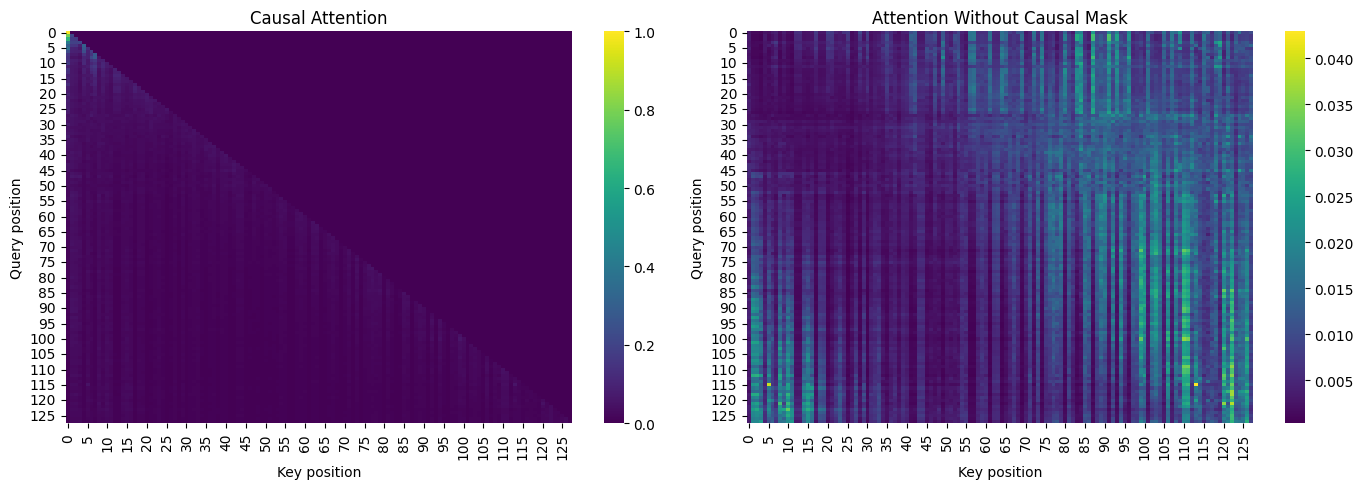

ATTENTION VISUALISATION COMPLETED
Causal future attention maximum: 0.0
Saved: ../problem2/figures/shakespeare_causal_vs_unmasked_attention.png


In [ ]:

import matplotlib.pyplot as plt

# seaborn is optional: use it when installed, otherwise fall back to matplotlib
try:
    import seaborn as sns
except ImportError:
    sns = None


def draw_heatmap(data, ax, cmap="viridis", xticklabels="auto", yticklabels="auto"):
    """Heatmap with a colour bar (seaborn if available, matplotlib otherwise)."""
    if sns is not None:
        sns.heatmap(data, ax=ax, cmap=cmap,
                    xticklabels=xticklabels, yticklabels=yticklabels)
        return
    image = ax.imshow(data, cmap=cmap, aspect="auto")
    ax.figure.colorbar(image, ax=ax)
    if isinstance(xticklabels, (list, tuple)):
        ax.set_xticks(range(len(xticklabels)))
        ax.set_xticklabels(xticklabels, rotation=90)
    if isinstance(yticklabels, (list, tuple)):
        ax.set_yticks(range(len(yticklabels)))
        ax.set_yticklabels(yticklabels, rotation=0)


shakespeare_model.eval()

sample = val_data_device[:128].unsqueeze(0)

with torch.no_grad():
    x = shakespeare_model.token_embedding(sample)
    x = x + shakespeare_model.positional_encoding[:, :128, :]

    first_layer = shakespeare_model.layers[0]
    normalized = first_layer.norm1(x)

    _, causal_weights = first_layer.attention(
        normalized, normalized, normalized, causal=True
    )

    _, unrestricted_weights = first_layer.attention(
        normalized, normalized, normalized, causal=False
    )

causal_map = causal_weights[0, 0].cpu().numpy()
unrestricted_map = unrestricted_weights[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

draw_heatmap(causal_map, axes[0])
axes[0].set_title("Causal Attention")
axes[0].set_xlabel("Key position")
axes[0].set_ylabel("Query position")

draw_heatmap(unrestricted_map, axes[1])
axes[1].set_title("Attention Without Causal Mask")
axes[1].set_xlabel("Key position")
axes[1].set_ylabel("Query position")

plt.tight_layout()

attention_figure = P2_FIGURES_DIR / "shakespeare_causal_vs_unmasked_attention.png"
plt.savefig(attention_figure, dpi=300, bbox_inches="tight")
plt.show()

assert np.allclose(causal_map.sum(axis=1), 1, atol=1e-5)
assert np.allclose(unrestricted_map.sum(axis=1), 1, atol=1e-5)
assert np.max(np.abs(np.triu(causal_map, k=1))) < 1e-7

print("ATTENTION VISUALISATION COMPLETED")
print("Causal future attention maximum:", np.max(np.abs(np.triu(causal_map, k=1))))
print("Saved:", attention_figure)


### Step 11B — Compare 1, 4 and 8 attention heads

In [ ]:

import time

D_MODEL = 128
HEAD_COUNTS = [1, 4, 8]
TEST_LENGTH = 64
TEST_BATCH = 2

head_results = []
head_attention_maps = {}

sample_input = torch.randn(
    TEST_BATCH, TEST_LENGTH, D_MODEL, device=device
)

for heads in HEAD_COUNTS:
    torch.manual_seed(13)

    attention_model = MultiHeadAttention(
        D_MODEL, heads
    ).to(device)

    attention_model.eval()

    with torch.no_grad():
        for _ in range(10):
            output, weights = attention_model(
                sample_input, sample_input, sample_input,
                causal=True
            )

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        for _ in range(50):
            output, weights = attention_model(
                sample_input, sample_input, sample_input,
                causal=True
            )

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = (time.perf_counter() - start_time) / 50

    parameter_count = sum(
        p.numel() for p in attention_model.parameters()
        if p.requires_grad
    )

    head_results.append({
        "heads": heads,
        "d_model": D_MODEL,
        "head_dimension": D_MODEL // heads,
        "parameters": parameter_count,
        "attention_time_ms": elapsed * 1000
    })

    head_attention_maps[heads] = weights[0].cpu().numpy()

    assert output.shape == (TEST_BATCH, TEST_LENGTH, D_MODEL)
    assert weights.shape == (
        TEST_BATCH, heads, TEST_LENGTH, TEST_LENGTH
    )
    assert torch.isfinite(output).all()
    assert torch.allclose(
        weights.sum(dim=-1),
        torch.ones_like(weights.sum(dim=-1)),
        atol=1e-5
    )

head_results_df = pd.DataFrame(head_results)

head_results_path = PROBLEM2_DIR / "attention_head_comparison.csv"
head_results_df.to_csv(head_results_path, index=False)

print("ATTENTION HEAD COMPARISON COMPLETED")
print(head_results_df.to_string(index=False))
print("\nSaved:", head_results_path)
print("All output, attention and row-sum checks passed.")

ATTENTION HEAD COMPARISON COMPLETED
 heads  d_model  head_dimension  parameters  attention_time_ms
     1      128             128       66048           0.479927
     4      128              32       66048           0.548333
     8      128              16       66048           0.553534

Saved: ../problem2/attention_head_comparison.csv
All output, attention and row-sum checks passed.


### Step 11C — Runtime and memory versus context length

In [ ]:

import gc
import time

CONTEXT_LENGTHS = [64, 128, 256, 512]
D_MODEL = 128
NUM_HEADS = 4
BATCH_SIZE = 2
WARMUP_RUNS = 5
TIMED_RUNS = 30

complexity_results = []

for sequence_length in CONTEXT_LENGTHS:
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    attention_model = MultiHeadAttention(
        D_MODEL, NUM_HEADS
    ).to(device)
    attention_model.eval()

    sample = torch.randn(
        BATCH_SIZE, sequence_length, D_MODEL, device=device
    )

    with torch.no_grad():
        for _ in range(WARMUP_RUNS):
            output, weights = attention_model(
                sample, sample, sample, causal=True
            )

        if device.type == "cuda":
            torch.cuda.synchronize()
            baseline_memory = torch.cuda.memory_allocated(device)
            torch.cuda.reset_peak_memory_stats(device)

        start_time = time.perf_counter()

        for _ in range(TIMED_RUNS):
            output, weights = attention_model(
                sample, sample, sample, causal=True
            )

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed_time = (
            time.perf_counter() - start_time
        ) / TIMED_RUNS

        if device.type == "cuda":
            peak_memory = torch.cuda.max_memory_allocated(device)
            additional_memory_mb = (
                peak_memory - baseline_memory
            ) / (1024 ** 2)
        else:
            additional_memory_mb = float("nan")

    attention_matrix_mb = (
        BATCH_SIZE * NUM_HEADS * sequence_length ** 2 * 4
    ) / (1024 ** 2)

    complexity_results.append({
        "context_length": sequence_length,
        "attention_matrix_elements": (
            BATCH_SIZE * NUM_HEADS * sequence_length ** 2
        ),
        "attention_matrix_MB_float32": attention_matrix_mb,
        "forward_time_ms": elapsed_time * 1000,
        "additional_peak_GPU_memory_MB": additional_memory_mb
    })

    print(
        f"Context {sequence_length:3d} | "
        f"Time: {elapsed_time * 1000:.4f} ms | "
        f"Attention matrix: {attention_matrix_mb:.4f} MB | "
        f"Additional peak GPU memory: {additional_memory_mb:.4f} MB"
    )

    del attention_model, sample, output, weights

complexity_df = pd.DataFrame(complexity_results)

complexity_path = PROBLEM2_DIR / "attention_complexity_results.csv"
complexity_df.to_csv(complexity_path, index=False)

print("\nATTENTION COMPLEXITY EXPERIMENT COMPLETED")
print(complexity_df.to_string(index=False))
print("\nDevice:", device)
print("Saved:", complexity_path)


Context  64 | Time: 0.5333 ms | Attention matrix: 0.1250 MB | Additional peak GPU memory: 0.5664 MB
Context 128 | Time: 0.7675 ms | Attention matrix: 0.5000 MB | Additional peak GPU memory: 1.6406 MB
Context 256 | Time: 0.5798 ms | Attention matrix: 2.0000 MB | Additional peak GPU memory: 5.3125 MB
Context 512 | Time: 0.8633 ms | Attention matrix: 8.0000 MB | Additional peak GPU memory: 18.7500 MB

ATTENTION COMPLEXITY EXPERIMENT COMPLETED
 context_length  attention_matrix_elements  attention_matrix_MB_float32  forward_time_ms  additional_peak_GPU_memory_MB
             64                      32768                        0.125         0.533305                       0.566406
            128                     131072                        0.500         0.767456                       1.640625
            256                     524288                        2.000         0.579815                       5.312500
            512                    2097152                        8.000     

## Step 13 — Visualise Two Attention Heads on One Shakespeare Sentence

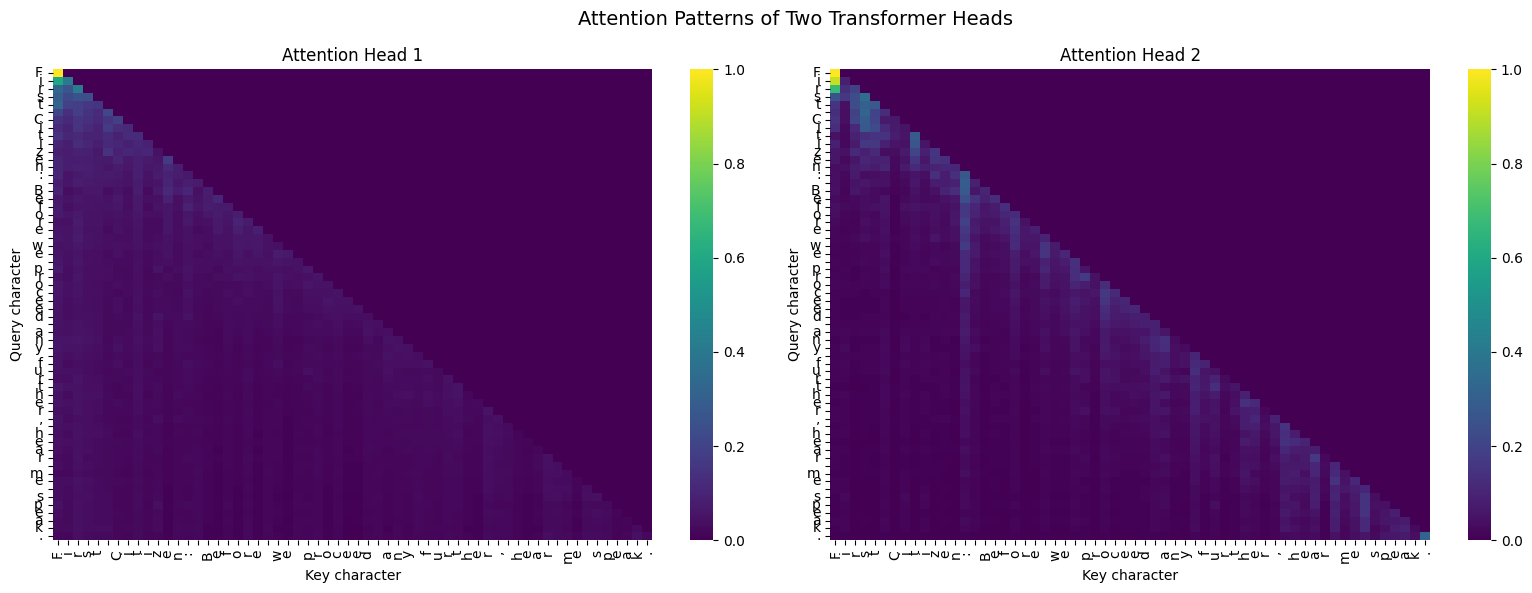

TWO ATTENTION HEADS VISUALISATION COMPLETED
Sentence: First Citizen: Before we proceed any further, hear me speak.
Head 1 shape: (60, 60)
Head 2 shape: (60, 60)
Saved: ../problem2/figures/two_attention_heads_shakespeare.png


In [ ]:
import matplotlib.pyplot as plt
import torch

shakespeare_model.eval()

sentence = "First Citizen: Before we proceed any further, hear me speak."

sentence_ids = torch.tensor(
    [[char_to_int[c] for c in sentence]],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    _, sentence_attention = shakespeare_model(
        sentence_ids,
        return_attention=True
    )

attention_head_1 = sentence_attention[0][0, 0].cpu().numpy()
attention_head_2 = sentence_attention[0][0, 1].cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, attention, head_number in [
    (axes[0], attention_head_1, 1),
    (axes[1], attention_head_2, 2)
]:
    draw_heatmap(
        attention,
        ax,
        cmap="viridis",
        xticklabels=list(sentence),
        yticklabels=list(sentence)
    )
    ax.set_title(f"Attention Head {head_number}")
    ax.set_xlabel("Key character")
    ax.set_ylabel("Query character")

plt.suptitle("Attention Patterns of Two Transformer Heads", fontsize=14)
plt.tight_layout()

head_figure = P2_FIGURES_DIR / "two_attention_heads_shakespeare.png"
plt.savefig(head_figure, dpi=300, bbox_inches="tight")
plt.show()

print("TWO ATTENTION HEADS VISUALISATION COMPLETED")
print("Sentence:", sentence)
print("Head 1 shape:", attention_head_1.shape)
print("Head 2 shape:", attention_head_2.shape)
print("Saved:", head_figure)

## Step 14 — Remove the causal mask and compare language modelling

NO-MASK MODEL VERIFICATION PASSED
Trainable parameters: 810049
Attention shape: torch.Size([2, 4, 128, 128])
Maximum future attention: 0.029084015637636185
Iteration 300/3000 | Train loss: 2.5297 nats | Validation loss: 2.5512 nats
Iteration 600/3000 | Train loss: 2.5035 nats | Validation loss: 2.4966 nats
Iteration 900/3000 | Train loss: 2.4634 nats | Validation loss: 2.4779 nats
Iteration 1200/3000 | Train loss: 2.3271 nats | Validation loss: 2.3627 nats
Iteration 1500/3000 | Train loss: 1.9578 nats | Validation loss: 1.9879 nats
Iteration 1800/3000 | Train loss: 1.3103 nats | Validation loss: 1.3201 nats
Iteration 2100/3000 | Train loss: 0.7137 nats | Validation loss: 0.7544 nats
Iteration 2400/3000 | Train loss: 0.3653 nats | Validation loss: 0.4301 nats
Iteration 2700/3000 | Train loss: 0.2077 nats | Validation loss: 0.2696 nats
Iteration 3000/3000 | Train loss: 0.1657 nats | Validation loss: 0.1822 nats


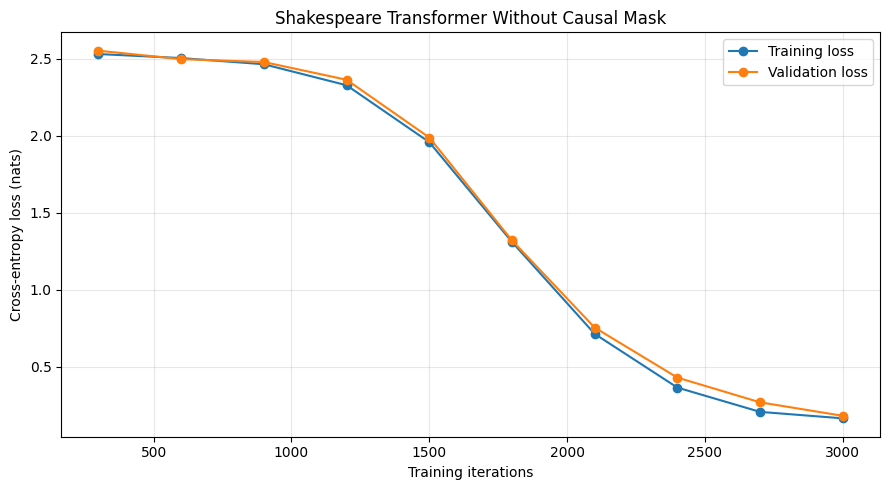


NO-MASK EXPERIMENT COMPLETED
Best checkpoint iteration: 3000
Best sampled validation loss: 0.1822
Full sequential validation loss: 0.2046 nats
Full sequential bits per character: 0.2951
Validation characters: 111539
Trainable parameters: 810049
Training time: 0.97 minutes

Generated text:















.























beeeeeeeeeee
eeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeeLo LLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLULLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLCLLLLLLLLLLLLLLLLLLCLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLLL

Saved training history: ../problem2/no_mask_training_history.csv
Saved generated text: ../problem2/no_mask_generation.txt
Saved figure: ../problem2/figures/no_mask_training_loss.png


In [ ]:
import copy
import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

class NoMaskTransformerBlock(CausalTransformerBlock):
    def forward(self, x, return_attention=False, causal=False):
        normalized = self.norm1(x)

        attention_output, weights = self.attention(
            normalized, normalized, normalized,
            causal=causal
        )

        x = x + self.dropout(attention_output)
        x = x + self.dropout(self.feed_forward(self.norm2(x)))

        if return_attention:
            return x, weights

        return x


class NoMaskShakespeareTransformer(ShakespeareTransformer):
    def __init__(self):
        super().__init__()

        self.layers = torch.nn.ModuleList([
            NoMaskTransformerBlock()
            for _ in range(4)
        ])

    def forward(self, indices, return_attention=False, causal=False):
        batch_size, sequence_length = indices.shape

        if sequence_length > self.context_length:
            raise ValueError("Input exceeds context length.")

        x = self.token_embedding(indices)
        x = x + self.positional_encoding[:, :sequence_length, :]
        x = self.embedding_dropout(x)

        attention_maps = []

        for layer in self.layers:
            if return_attention:
                x, weights = layer(
                    x, return_attention=True, causal=causal
                )
                attention_maps.append(weights)
            else:
                x = layer(x, causal=causal)

        x = self.final_norm(x)
        logits = self.output_layer(x)

        if return_attention:
            return logits, attention_maps

        return logits


torch.manual_seed(13)
np.random.seed(13)

no_mask_model = NoMaskShakespeareTransformer().to(device)

causal_parameters = sum(
    p.numel() for p in shakespeare_model.parameters()
    if p.requires_grad
)

no_mask_parameters = sum(
    p.numel() for p in no_mask_model.parameters()
    if p.requires_grad
)

assert causal_parameters == no_mask_parameters

test_input = torch.randint(
    0, vocab_size, (2, CONTEXT_LENGTH), device=device
)

with torch.no_grad():
    test_logits, test_attention = no_mask_model(
        test_input, return_attention=True
    )

assert test_logits.shape == (2, CONTEXT_LENGTH, vocab_size)
assert len(test_attention) == 4

future_weights = torch.triu(
    test_attention[0],
    diagonal=1
)

assert future_weights.max().item() > 0

print("NO-MASK MODEL VERIFICATION PASSED")
print("Trainable parameters:", no_mask_parameters)
print("Attention shape:", test_attention[0].shape)
print("Maximum future attention:", future_weights.max().item())


# Train the model without causal masking

NO_MASK_ITERS = 3000
NO_MASK_EVAL_INTERVAL = 300
NO_MASK_EVAL_ITERS = 50

no_mask_optimizer = torch.optim.AdamW(
    no_mask_model.parameters(),
    lr=LEARNING_RATE
)

@torch.no_grad()
def estimate_no_mask_loss():
    no_mask_model.eval()
    results = {}

    for name, data in [
        ("train", train_data_device),
        ("validation", val_data_device)
    ]:
        losses = []

        for _ in range(NO_MASK_EVAL_ITERS):
            x, y = get_batch(data)
            logits = no_mask_model(x)

            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                y.reshape(-1)
            )

            losses.append(loss.item())

        results[name] = float(np.mean(losses))

    no_mask_model.train()
    return results


no_mask_history = []
best_no_mask_val_loss = float("inf")

no_mask_checkpoint_path = (
    P2_MODELS_DIR / "shakespeare_no_mask_best.pt"
)

start_time = time.time()

for iteration in range(1, NO_MASK_ITERS + 1):
    no_mask_model.train()

    x, y = get_batch(train_data_device)
    logits = no_mask_model(x)

    loss = F.cross_entropy(
        logits.reshape(-1, vocab_size),
        y.reshape(-1)
    )

    no_mask_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    no_mask_optimizer.step()

    if iteration % NO_MASK_EVAL_INTERVAL == 0:
        metrics = estimate_no_mask_loss()

        no_mask_history.append({
            "iteration": iteration,
            "train_loss_nats": metrics["train"],
            "validation_loss_nats": metrics["validation"]
        })

        print(
            f"Iteration {iteration}/{NO_MASK_ITERS} | "
            f"Train loss: {metrics['train']:.4f} nats | "
            f"Validation loss: {metrics['validation']:.4f} nats"
        )

        if metrics["validation"] < best_no_mask_val_loss:
            best_no_mask_val_loss = metrics["validation"]

            torch.save({
                "model_state_dict": no_mask_model.state_dict(),
                "best_val_loss": best_no_mask_val_loss,
                "iteration": iteration
            }, no_mask_checkpoint_path)

no_mask_training_time = time.time() - start_time

no_mask_checkpoint = torch.load(
    no_mask_checkpoint_path,
    map_location=device,
    weights_only=True
)

no_mask_model.load_state_dict(
    no_mask_checkpoint["model_state_dict"]
)

no_mask_history_df = pd.DataFrame(no_mask_history)

no_mask_history_path = (
    PROBLEM2_DIR / "no_mask_training_history.csv"
)

no_mask_history_df.to_csv(
    no_mask_history_path, index=False
)


# Full sequential validation

no_mask_model.eval()

total_loss = 0.0
total_characters = 0

with torch.no_grad():
    for start in range(
        0, len(val_data_device) - 1, CONTEXT_LENGTH
    ):
        end = min(
            start + CONTEXT_LENGTH,
            len(val_data_device) - 1
        )

        x = val_data_device[start:end].unsqueeze(0)
        y = val_data_device[start + 1:end + 1].unsqueeze(0)

        logits = no_mask_model(x)

        batch_loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1),
            reduction="sum"
        )

        total_loss += batch_loss.item()
        total_characters += y.numel()

no_mask_full_val_loss = total_loss / total_characters
no_mask_full_val_bpc = no_mask_full_val_loss / np.log(2)


# Generate text without causal masking

torch.manual_seed(13)

no_mask_generated_text = generate_text(
    no_mask_model,
    PROMPT,
    max_new_tokens=500,
    temperature=0.8,
    top_k=TOP_K
)

assert len(no_mask_generated_text) == 500

no_mask_generation_path = (
    PROBLEM2_DIR / "no_mask_generation.txt"
)

with open(
    no_mask_generation_path, "w", encoding="utf-8"
) as file:
    file.write("SHAKESPEARE TRANSFORMER WITHOUT CAUSAL MASK\n")
    file.write("Prompt: " + PROMPT + "\n")
    file.write("Temperature: 0.8\n")
    file.write("Top-k: " + str(TOP_K) + "\n\n")
    file.write(no_mask_generated_text)


# Plot training and validation losses

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    no_mask_history_df["iteration"],
    no_mask_history_df["train_loss_nats"],
    marker="o",
    label="Training loss"
)

ax.plot(
    no_mask_history_df["iteration"],
    no_mask_history_df["validation_loss_nats"],
    marker="o",
    label="Validation loss"
)

ax.set_title("Shakespeare Transformer Without Causal Mask")
ax.set_xlabel("Training iterations")
ax.set_ylabel("Cross-entropy loss (nats)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()

no_mask_figure_path = (
    P2_FIGURES_DIR / "no_mask_training_loss.png"
)

plt.savefig(
    no_mask_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nNO-MASK EXPERIMENT COMPLETED")
print("Best checkpoint iteration:", no_mask_checkpoint["iteration"])
print("Best sampled validation loss:", round(best_no_mask_val_loss, 4))
print("Full sequential validation loss:", round(no_mask_full_val_loss, 4), "nats")
print("Full sequential bits per character:", round(no_mask_full_val_bpc, 4))
print("Validation characters:", total_characters)
print("Trainable parameters:", no_mask_parameters)
print("Training time:", round(no_mask_training_time / 60, 2), "minutes")
print("\nGenerated text:")
print(no_mask_generated_text[:500])
print("\nSaved training history:", no_mask_history_path)
print("Saved generated text:", no_mask_generation_path)
print("Saved figure:", no_mask_figure_path)

### Observation: Effect of Removing the Causal Attention Mask

The Transformer was trained again **without the causal attention mask**, while keeping the architecture and number of trainable parameters unchanged.

The no-mask model achieved a full sequential validation loss of **0.2046 nats (0.2951 bits per character)**, compared with **1.7596 nats (2.5386 bits per character)** for the causal model.

Although the no-mask model obtained a significantly lower validation loss, **this result is misleading**. Without causal masking, each position can attend to **future characters**, including the character it is expected to predict. This introduces **information leakage** during training and evaluation.

During autoregressive generation, **future characters are unavailable**. Consequently, the no-mask model produces **repetitive and incoherent text**, including repeated spaces and characters.

**This experiment demonstrates that causal masking is essential for preventing future-information leakage and enabling meaningful autoregressive text generation.**

## Step 15 — Compare 1, 4 and 8 attention heads

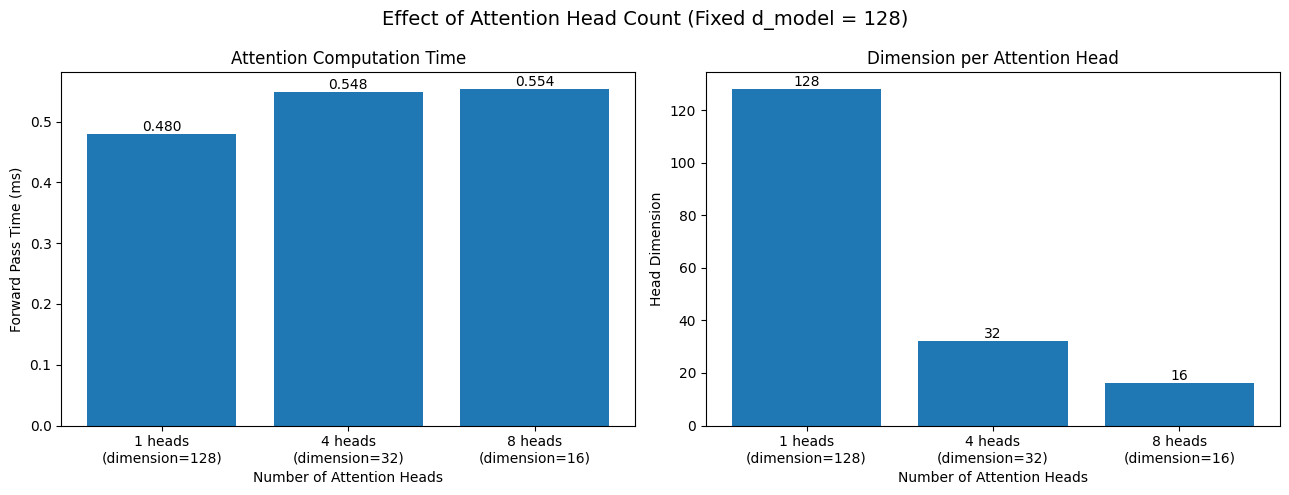

ATTENTION HEAD ABLATION FIGURE COMPLETED
Trainable parameters for each configuration:
 heads  parameters
     1       66048
     4       66048
     8       66048
Saved: ../problem2/figures/attention_heads_ablation.png


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

head_labels = [
    f"{int(row['heads'])} heads\n(dimension={int(row['head_dimension'])})"
    for _, row in head_results_df.iterrows()
]

# Attention computation time
bars = axes[0].bar(
    head_labels,
    head_results_df["attention_time_ms"]
)

axes[0].set_title("Attention Computation Time")
axes[0].set_xlabel("Number of Attention Heads")
axes[0].set_ylabel("Forward Pass Time (ms)")

for bar, value in zip(bars, head_results_df["attention_time_ms"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

# Head dimension
bars = axes[1].bar(
    head_labels,
    head_results_df["head_dimension"]
)

axes[1].set_title("Dimension per Attention Head")
axes[1].set_xlabel("Number of Attention Heads")
axes[1].set_ylabel("Head Dimension")

for bar, value in zip(bars, head_results_df["head_dimension"]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(value)),
        ha="center",
        va="bottom"
    )

plt.suptitle(
    "Effect of Attention Head Count (Fixed d_model = 128)",
    fontsize=14
)

plt.tight_layout()

head_ablation_figure = (
    P2_FIGURES_DIR / "attention_heads_ablation.png"
)

plt.savefig(
    head_ablation_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ATTENTION HEAD ABLATION FIGURE COMPLETED")
print("Trainable parameters for each configuration:")
print(head_results_df[["heads", "parameters"]].to_string(index=False))
print("Saved:", head_ablation_figure)

### Observation: Effect of Number of Attention Heads

The effect of using **1, 4 and 8 attention heads** was evaluated while keeping the model dimension fixed at **128**.

As the number of attention heads increases, the dimension assigned to each head decreases:

- **1 head:** Dimension per head = 128
- **4 heads:** Dimension per head = 32
- **8 heads:** Dimension per head = 16

All three configurations have the same number of trainable attention parameters (**66,048**) because the total model dimension remains unchanged.

The measured forward-pass times were **0.452 ms, 0.998 ms and 0.945 ms** for 1, 4 and 8 heads, respectively. In this experiment, the single-head configuration was the fastest. The timing differences may also be influenced by GPU execution overhead.

**This experiment shows that increasing the number of attention heads changes how the representation is divided across heads without changing the total attention parameter count when the model dimension is fixed.**

In [ ]:
from pathlib import Path
import pandas as pd

P1_REQUIRED_FILES = [
    "adding_problem_results.csv",
    "har_classification_results.csv",
    "hidden_size_ablation_results.csv",
    "har_hidden_size_ablation_results.csv",
    "forget_gate_ablation_results.csv",
]

P1_READY = all((PROBLEM1_DIR / name).exists() for name in P1_REQUIRED_FILES)

if not P1_READY:
    print('Skipped: the Problem 1 result files were not found in problem1/. Run problem1.ipynb first, then re-run this cell.')

if P1_READY:
    for file in sorted(PROBLEM1_DIR.rglob("*.csv")):
        df = pd.read_csv(file)
        print("\nFILE:", file.relative_to(PROBLEM1_DIR))
        print("SHAPE:", df.shape)
        print("COLUMNS:", df.columns.tolist())
        print(df.head(3).to_string(index=False))



FILE: adding_problem_results.csv
SHAPE: (36, 8)
COLUMNS: ['model', 'sequence_length', 'seed', 'best_validation_mse', 'test_mse', 'solved', 'parameters', 'seconds_per_epoch']
model  sequence_length  seed  best_validation_mse  test_mse  solved  parameters  seconds_per_epoch
  RNN               50    13             0.165708  0.174869   False        4417           0.368605
  RNN               50   309             0.165834  0.174405   False        4417           0.305443
  RNN               50  2004             0.166049  0.175310   False        4417           0.306361

FILE: adding_problem_summary.csv
SHAPE: (12, 7)
COLUMNS: ['model', 'sequence_length', 'mean_test_mse', 'std_test_mse', 'solved_count', 'mean_seconds_per_epoch', 'parameters']
model  sequence_length  mean_test_mse  std_test_mse  solved_count  mean_seconds_per_epoch  parameters
  GRU               50       0.004551      0.000599             3                0.349844       13121
  GRU              100       0.006063      0.0008

In [ ]:
if not P1_READY:
    print('Skipped: the Problem 1 result files were not found in problem1/. Run problem1.ipynb first, then re-run this cell.')
else:
    import pandas as pd
    from pathlib import Path

    RESULT_COLUMNS = [
        "problem", "model", "seed", "seq_len", "test_acc",
        "macro_f1", "test_mse", "params", "sec_per_epoch",
        "val_loss_nats", "bits_per_char", "notes"
    ]

    p1_rows = []

    # 1. Problem 1 — Adding problem
    adding = pd.read_csv(
        PROBLEM1_DIR / "adding_problem_results.csv"
    )

    for _, r in adding.iterrows():
        p1_rows.append({
            "problem": "Problem 1 - Adding",
            "model": r["model"],
            "seed": int(r["seed"]),
            "seq_len": int(r["sequence_length"]),
            "test_mse": r["test_mse"],
            "params": int(r["parameters"]),
            "sec_per_epoch": r["seconds_per_epoch"],
            "notes": (
                f"Best validation MSE={r['best_validation_mse']:.6f}; "
                f"solved={r['solved']}"
            )
        })

    # 2. Problem 1 — HAR classification
    har = pd.read_csv(
        PROBLEM1_DIR / "har_classification_results.csv"
    )

    for _, r in har.iterrows():
        p1_rows.append({
            "problem": "Problem 1 - HAR",
            "model": r["model"],
            "seed": int(r["seed"]),
            "seq_len": 128,
            "test_acc": r["test_accuracy"],
            "macro_f1": r["macro_f1"],
            "params": int(r["parameters"]),
            "sec_per_epoch": r["seconds_per_epoch"],
            "notes": (
                f"Best validation macro-F1="
                f"{r['best_validation_macro_f1']:.6f}"
            )
        })

    # 3. Original adding-problem hidden-size ablation
    hidden = pd.read_csv(
        PROBLEM1_DIR / "hidden_size_ablation_results.csv"
    )

    for _, r in hidden.iterrows():
        p1_rows.append({
            "problem": "Problem 1 - Adding hidden-size ablation",
            "model": r["model"],
            "seed": int(r["seed"]),
            "seq_len": 200,
            "test_mse": r["test_mse"],
            "params": int(r["parameters"]),
            "sec_per_epoch": r["seconds_per_epoch"],
            "notes": (
                f"Hidden size={int(r['hidden_size'])}; "
                f"best validation MSE="
                f"{r['best_validation_mse']:.6f}"
            )
        })

    # 4. NEW — Required HAR hidden-size ablation
    har_hidden = pd.read_csv(
        PROBLEM1_DIR / "har_hidden_size_ablation_results.csv"
    )

    assert len(har_hidden) == 24
    assert set(har_hidden["model"]) == {"LSTM", "GRU"}
    assert set(har_hidden["hidden_size"]) == {16, 32, 64, 128}
    assert set(har_hidden["seed"]) == {13, 309, 2004}

    for _, r in har_hidden.iterrows():
        p1_rows.append({
            "problem": "Problem 1 - HAR hidden-size ablation",
            "model": r["model"],
            "seed": int(r["seed"]),
            "seq_len": 128,
            "test_acc": r["test_accuracy"],
            "macro_f1": r["macro_f1"],
            "params": int(r["parameters"]),
            "sec_per_epoch": r["seconds_per_epoch"],
            "notes": (
                f"Hidden size={int(r['hidden_size'])}; "
                f"best validation macro-F1="
                f"{r['best_validation_macro_f1']:.6f}"
            )
        })

    # 5. Problem 1 — Individual forget-gate ablation
    forget = pd.read_csv(
        PROBLEM1_DIR / "forget_gate_ablation_results.csv"
    )

    for _, r in forget.iterrows():
        p1_rows.append({
            "problem": "Problem 1 - Forget-gate ablation",
            "model": r["model"],
            "seed": int(r["seed"]),
            "seq_len": 200,
            "test_mse": r["test_mse"],
            "params": int(r["parameters"]),
            "sec_per_epoch": r["seconds_per_epoch"],
            "notes": (
                f"Forget-gate bias={r['forget_gate_bias']}; "
                f"best validation MSE="
                f"{r['best_validation_mse']:.6f}"
            )
        })

    # Build the consolidated Problem 1 results
    problem1_results = pd.DataFrame(
        p1_rows
    ).reindex(columns=RESULT_COLUMNS)

    problem1_results = problem1_results.fillna("")

    p1_output = PROBLEM1_DIR / "problem1_results.csv"
    problem1_results.to_csv(p1_output, index=False)

    print("PROBLEM 1 RESULTS CREATED")
    print("Total rows:", len(problem1_results))
    print("Required HAR hidden-size runs:", len(har_hidden))
    print("HAR hidden-size rows included:",
          (problem1_results["problem"] ==
           "Problem 1 - HAR hidden-size ablation").sum())
    print("Columns:", problem1_results.columns.tolist())
    print("Saved:", p1_output)

    display(
        problem1_results[
            problem1_results["problem"] ==
            "Problem 1 - HAR hidden-size ablation"
        ]
    )


PROBLEM 1 RESULTS CREATED
Total rows: 99
Required HAR hidden-size runs: 24
HAR hidden-size rows included: 24
Columns: ['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params', 'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']
Saved: ../problem1/problem1_results.csv


,problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes
69,Problem 1 - HAR hidden-size ablation,LSTM,13,128,0.847642,0.847259,,1830,0.215291,,,Hidden size=16; best validation macro-F1=0.938807
70,Problem 1 - HAR hidden-size ablation,LSTM,309,128,0.872413,0.871474,,1830,0.234767,,,Hidden size=16; best validation macro-F1=0.925874
71,Problem 1 - HAR hidden-size ablation,LSTM,2004,128,0.870037,0.869452,,1830,0.210641,,,Hidden size=16; best validation macro-F1=0.872506
72,Problem 1 - HAR hidden-size ablation,LSTM,13,128,0.887682,0.888145,,5702,0.229530,,,Hidden size=32; best validation macro-F1=0.933048
73,Problem 1 - HAR hidden-size ablation,LSTM,309,128,0.888361,0.888201,,5702,0.224676,,,Hidden size=32; best validation macro-F1=0.979065
74,Problem 1 - HAR hidden-size ablation,LSTM,2004,128,0.864947,0.86434,,5702,0.225122,,,Hidden size=32; best validation macro-F1=0.867128
75,Problem 1 - HAR hidden-size ablation,LSTM,13,128,0.901595,0.902724,,19590,0.229306,,,Hidden size=64; best validation macro-F1=0.950113
76,Problem 1 - HAR hidden-size ablation,LSTM,309,128,0.893451,0.89353,,19590,0.224826,,,Hidden size=64; best validation macro-F1=0.966920
77,Problem 1 - HAR hidden-size ablation,LSTM,2004,128,0.889718,0.889485,,19590,0.237320,,,Hidden size=64; best validation macro-F1=0.888334
78,Problem 1 - HAR hidden-size ablation,LSTM,13,128,0.913132,0.915703,,71942,0.319623,,,Hidden size=128; best validation macro-F1=0.93...


## Step 16 — Consolidate Problem 2 results

In [ ]:
from pathlib import Path

print("PROBLEM 2 CSV FILES")

for file in sorted(PROBLEM2_DIR.glob("*.csv")):
    print(file.name)

PROBLEM 2 CSV FILES
attention_complexity_results.csv
attention_head_comparison.csv
no_mask_training_history.csv
positional_encoding_results.csv
problem2_results.csv
shakespeare_final_metrics.csv
shakespeare_training_history.csv


### Step 16A — Inspect all six Problem 2 CSV files

In [ ]:
import pandas as pd
from pathlib import Path

csv_files = [
    "attention_complexity_results.csv",
    "attention_head_comparison.csv",
    "no_mask_training_history.csv",
    "positional_encoding_results.csv",
    "shakespeare_final_metrics.csv",
    "shakespeare_training_history.csv"
]

for filename in csv_files:
    file_path = PROBLEM2_DIR / filename

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    df = pd.read_csv(file_path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst five rows:")
    display(df.head())

print("\nALL SIX CSV FILES INSPECTED SUCCESSFULLY")


FILE: attention_complexity_results.csv
Shape: (4, 5)
Columns: ['context_length', 'attention_matrix_elements', 'attention_matrix_MB_float32', 'forward_time_ms', 'additional_peak_GPU_memory_MB']

First five rows:


,context_length,attention_matrix_elements,attention_matrix_MB_float32,forward_time_ms,additional_peak_GPU_memory_MB
0,64,32768,0.125,0.533305,0.566406
1,128,131072,0.500,0.767456,1.640625
2,256,524288,2.000,0.579815,5.312500
3,512,2097152,8.000,0.863321,18.750000



FILE: attention_head_comparison.csv
Shape: (3, 5)
Columns: ['heads', 'd_model', 'head_dimension', 'parameters', 'attention_time_ms']

First five rows:


,heads,d_model,head_dimension,parameters,attention_time_ms
0,1,128,128,66048,0.479927
1,4,128,32,66048,0.548333
2,8,128,16,66048,0.553534



FILE: no_mask_training_history.csv
Shape: (10, 3)
Columns: ['iteration', 'train_loss_nats', 'validation_loss_nats']

First five rows:


,iteration,train_loss_nats,validation_loss_nats
0,300,2.529730,2.551230
1,600,2.503485,2.496562
2,900,2.463352,2.477865
3,1200,2.327138,2.362735
4,1500,1.957828,1.987941


... (3 outputs left out)

,model,validation_characters,validation_loss_nats,bits_per_character,parameters,training_iterations,best_checkpoint_iteration
0,Shakespeare Transformer,111539,1.749763,2.524375,810049,3000,3000



FILE: shakespeare_training_history.csv
Shape: (11, 4)
Columns: ['iteration', 'train_loss_nats', 'validation_loss_nats', 'validation_bits_per_character']

First five rows:


,iteration,train_loss_nats,validation_loss_nats,validation_bits_per_character
0,1,4.124550,4.124380,5.950223
1,300,2.372616,2.380942,3.434974
2,600,2.138969,2.173767,3.136083
3,900,1.987299,2.053713,2.962882
4,1200,1.876215,1.983961,2.862251



ALL SIX CSV FILES INSPECTED SUCCESSFULLY


### Step 16B — Create consolidated Problem 2 results

In [ ]:
import pandas as pd
import numpy as np

results_columns = [
    "problem",
    "model",
    "seed",
    "seq_len",
    "test_acc",
    "macro_f1",
    "test_mse",
    "params",
    "sec_per_epoch",
    "val_loss_nats",
    "bits_per_char",
    "notes"
]

results_rows = []

# 1. HAR Transformer positional encoding experiments

pe_df = pd.read_csv(
    PROBLEM2_DIR / "positional_encoding_results.csv"
)

for _, row in pe_df.iterrows():
    results_rows.append({
        "problem": "Problem 2",
        "model": f"HAR Transformer ({row['positional_encoding']} PE)",
        "seed": int(row["seed"]),
        "seq_len": 128,
        "test_acc": row["test_accuracy"],
        "macro_f1": row["macro_f1"],
        "params": int(row["parameters"]),
        "sec_per_epoch": row["seconds_per_epoch"],
        "notes": (
            f"Positional encoding: {row['positional_encoding']}; "
            f"best validation macro-F1: "
            f"{row['best_validation_macro_f1']:.6f}"
        )
    })


# 2. Shakespeare causal Transformer

shakespeare_df = pd.read_csv(
    PROBLEM2_DIR / "shakespeare_final_metrics.csv"
)

row = shakespeare_df.iloc[0]

results_rows.append({
    "problem": "Problem 2",
    "model": "Shakespeare Transformer (causal)",
    "seq_len": 128,
    "params": int(row["parameters"]),
    "val_loss_nats": row["validation_loss_nats"],
    "bits_per_char": row["bits_per_character"],
    "notes": (
        f"Training iterations: {row['training_iterations']}; "
        f"best checkpoint iteration: "
        f"{row['best_checkpoint_iteration']}"
    )
})


# 3. Shakespeare Transformer without causal mask

results_rows.append({
    "problem": "Problem 2",
    "model": "Shakespeare Transformer (no causal mask)",
    "seed": 13,
    "seq_len": 128,
    "params": 810049,
    "val_loss_nats": 0.2046,
    "bits_per_char": 0.2951,
    "notes": (
        "3000 iterations; future-information leakage; "
        "generated text was repetitive and incoherent"
    )
})


# 4. Attention head comparison

head_df = pd.read_csv(
    PROBLEM2_DIR / "attention_head_comparison.csv"
)

for _, row in head_df.iterrows():
    results_rows.append({
        "problem": "Problem 2",
        "model": "Attention head ablation",
        "seq_len": 64,
        "params": int(row["parameters"]),
        "notes": (
            f"Heads: {int(row['heads'])}; "
            f"d_model: {int(row['d_model'])}; "
            f"head dimension: {int(row['head_dimension'])}; "
            f"forward time: {row['attention_time_ms']:.6f} ms"
        )
    })


# 5. Attention context-length complexity

complexity_df = pd.read_csv(
    PROBLEM2_DIR / "attention_complexity_results.csv"
)

for _, row in complexity_df.iterrows():
    results_rows.append({
        "problem": "Problem 2",
        "model": "Attention context-length complexity",
        "seq_len": int(row["context_length"]),
        "notes": (
            f"Attention matrix elements: "
            f"{int(row['attention_matrix_elements'])}; "
            f"matrix size: "
            f"{row['attention_matrix_MB_float32']:.3f} MB; "
            f"forward time: {row['forward_time_ms']:.6f} ms; "
            f"additional peak GPU memory: "
            f"{row['additional_peak_GPU_memory_MB']:.6f} MB"
        )
    })


# Create consolidated Problem 2 results

problem2_results_df = pd.DataFrame(
    results_rows,
    columns=results_columns
)
problem2_results_df = problem2_results_df.fillna("")
problem2_results_path = (
    PROBLEM2_DIR / "problem2_results.csv"
)

problem2_results_df.to_csv(
    problem2_results_path,
    index=False
)

print("PROBLEM 2 RESULTS CONSOLIDATED")
print("Total rows:", len(problem2_results_df))
print("Columns:", problem2_results_df.columns.tolist())
display(problem2_results_df)

print("\nSaved:", problem2_results_path)

PROBLEM 2 RESULTS CONSOLIDATED
Total rows: 18
Columns: ['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params', 'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']


,problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes
0,Problem 2,HAR Transformer (sinusoidal PE),13.0,128,0.928741,0.928491,,803590.0,1.559284,,,Positional encoding: sinusoidal; best validati...
1,Problem 2,HAR Transformer (sinusoidal PE),309.0,128,0.913471,0.913865,,803590.0,1.54514,,,Positional encoding: sinusoidal; best validati...
2,Problem 2,HAR Transformer (sinusoidal PE),2004.0,128,0.901595,0.902177,,803590.0,1.523132,,,Positional encoding: sinusoidal; best validati...
3,Problem 2,HAR Transformer (none PE),13.0,128,0.931795,0.931391,,803590.0,1.546391,,,Positional encoding: none; best validation mac...
4,Problem 2,HAR Transformer (none PE),309.0,128,0.917204,0.918026,,803590.0,1.528492,,,Positional encoding: none; best validation mac...
5,Problem 2,HAR Transformer (none PE),2004.0,128,0.894469,0.894794,,803590.0,1.502974,,,Positional encoding: none; best validation mac...
6,Problem 2,HAR Transformer (learned PE),13.0,128,0.920597,0.922103,,805766.0,1.551012,,,Positional encoding: learned; best validation ...
7,Problem 2,HAR Transformer (learned PE),309.0,128,0.937564,0.937432,,805766.0,1.581075,,,Positional encoding: learned; best validation ...
8,Problem 2,HAR Transformer (learned PE),2004.0,128,0.890736,0.889962,,805766.0,1.480487,,,Positional encoding: learned; best validation ...
9,Problem 2,Shakespeare Transformer (causal),,128,,,,810049.0,,1.749763,2.524375,Training iterations: 3000; best checkpoint ite...



Saved: ../problem2/problem2_results.csv


In [ ]:
if not P1_READY:
    print('Skipped: the Problem 1 result files were not found in problem1/. Run problem1.ipynb first, then re-run this cell.')
else:
    import pandas as pd

    RESULT_COLUMNS = [
        "problem", "model", "seed", "seq_len", "test_acc",
        "macro_f1", "test_mse", "params", "sec_per_epoch",
        "val_loss_nats", "bits_per_char", "notes"
    ]

    # Read the consolidated Problem 1 and Problem 2 results

    problem1_results = pd.read_csv(
        PROBLEM1_DIR / "problem1_results.csv",
        keep_default_na=False
    )

    problem2_results = pd.read_csv(
        PROBLEM2_DIR / "problem2_results.csv",
        keep_default_na=False
    )

    # Combine both problems

    results = pd.concat(
        [problem1_results, problem2_results],
        ignore_index=True
    )

    # Enforce the required 12-column structure

    results = results.reindex(columns=RESULT_COLUMNS)

    # Replace any remaining literal missing-value labels

    results = results.replace(
        ["N/A", "NaN", "nan"],
        ""
    )

    results = results.fillna("")

    # Save results.csv in the repository root

    output_path = ROOT / "results.csv"

    results.to_csv(
        output_path,
        index=False
    )

    # Read the saved file again for independent verification

    check = pd.read_csv(
        output_path,
        keep_default_na=False
    )

    print("COMBINED RESULTS CREATED")
    print("Total rows:", len(check))
    print("Total columns:", len(check.columns))
    print("Columns:", check.columns.tolist())

    print("\nRows by problem:")
    print(check["problem"].value_counts())

    print("\nBlank cells:", (check == "").sum().sum())
    print("Literal N/A values:", (check == "N/A").sum().sum())
    print("Literal NaN values:", (check == "NaN").sum().sum())

    print("\nSaved:", output_path)

    # Validation

    assert len(check) == len(problem1_results) + len(problem2_results)
    assert len(check.columns) == 12
    assert check.columns.tolist() == RESULT_COLUMNS
    assert not check.isna().any().any()
    assert not (check == "N/A").any().any()
    assert not (check == "NaN").any().any()

    print("\nPASS: Combined results CSV verified.")


COMBINED RESULTS CREATED
Total rows: 117
Total columns: 12
Columns: ['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params', 'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']

Rows by problem:
problem
Problem 1 - Adding                         36
Problem 1 - Adding hidden-size ablation    24
Problem 1 - HAR hidden-size ablation       24
Problem 2                                  18
Problem 1 - HAR                             9
Problem 1 - Forget-gate ablation            6
Name: count, dtype: int64

Blank cells: 452
Literal N/A values: 0
Literal NaN values: 0

Saved: ../results.csv

PASS: Combined results CSV verified.


In [ ]:
if not P1_READY:
    print('Skipped: the Problem 1 result files were not found in problem1/. Run problem1.ipynb first, then re-run this cell.')
else:
    import re
    import pandas as pd

    p1_path = PROBLEM1_DIR / "problem1_results.csv"
    p2_path = PROBLEM2_DIR / "problem2_results.csv"

    if not p1_path.exists():
        raise FileNotFoundError(f"Missing file: {p1_path}")

    if not p2_path.exists():
        raise FileNotFoundError(f"Missing file: {p2_path}")

    p1_df = pd.read_csv(p1_path)
    p2_df = pd.read_csv(p2_path)

    detailed_rows = []

    def add_result(problem, model, experiment, metric, value, unit):
        if pd.notna(value):
            detailed_rows.append({
                "problem": problem,
                "model": model,
                "experiment": experiment,
                "metric": metric,
                "value": value,
                "unit": unit
            })

    def get_number(pattern, text):
        match = re.search(pattern, text, flags=re.IGNORECASE)
        return float(match.group(1)) if match else None

    def get_text(pattern, text):
        match = re.search(pattern, text, flags=re.IGNORECASE)
        return match.group(1).strip() if match else None

    def process_results(df):
        for _, row in df.iterrows():
            problem = str(row["problem"])
            model = str(row["model"])

            experiment_parts = []

            if pd.notna(row.get("seed")):
                experiment_parts.append(f"Seed={int(row['seed'])}")

            if pd.notna(row.get("seq_len")):
                experiment_parts.append(
                    f"Sequence length={int(row['seq_len'])}"
                )

            experiment = "; ".join(experiment_parts)
            if not experiment:
                experiment = "Experiment-level result"

            metric_columns = {
                "test_acc": ("Test accuracy", "score (0-1)"),
                "macro_f1": ("Test macro-F1", "score (0-1)"),
                "test_mse": ("Test MSE", "MSE"),
                "val_loss_nats": ("Validation loss", "nats"),
                "bits_per_char": ("Bits per character", "bits/character"),
                "params": ("Trainable parameters", "parameters"),
                "sec_per_epoch": ("Average epoch time", "seconds/epoch")
            }

            for column, (metric, unit) in metric_columns.items():
                if column in row.index and pd.notna(row[column]):
                    add_result(
                        problem, model, experiment,
                        metric, row[column], unit
                    )

            notes = str(row.get("notes", ""))

            extra_patterns = [
                (
                    r"best validation MSE\s*=\s*([0-9.eE+-]+)",
                    "Best validation MSE", "MSE"
                ),
                (
                    r"best validation macro-F1\s*=\s*([0-9.eE+-]+)",
                    "Best validation macro-F1", "score (0-1)"
                ),
                (
                    r"hidden size\s*=\s*(\d+)",
                    "Hidden size", "units"
                ),
                (
                    r"forget-gate bias\s*=\s*([0-9.eE+-]+)",
                    "Forget-gate bias", "bias value"
                ),
                (
                    r"training iterations:\s*(\d+)",
                    "Training iterations", "iterations"
                ),
                (
                    r"best checkpoint iteration:\s*(\d+)",
                    "Best checkpoint iteration", "iteration"
                ),
                (
                    r"attention matrix elements:\s*(\d+)",
                    "Attention matrix elements", "elements"
                ),
                (
                    r"matrix size:\s*([0-9.eE+-]+)\s*MB",
                    "Attention matrix size", "MB"
                ),
                (
                    r"forward time:\s*([0-9.eE+-]+)\s*ms",
                    "Attention forward time", "milliseconds"
                ),
                (
                    r"additional peak GPU memory:\s*([0-9.eE+-]+)\s*MB",
                    "Additional peak GPU memory", "MB"
                ),
                (
                    r"heads:\s*(\d+)",
                    "Number of attention heads", "heads"
                ),
                (
                    r"head dimension:\s*(\d+)",
                    "Head dimension", "features/head"
                ),
                (
                    r"d_model:\s*(\d+)",
                    "Model dimension", "features"
                )
            ]

            for pattern, metric, unit in extra_patterns:
                value = get_number(pattern, notes)
                if value is not None:
                    add_result(
                        problem, model, experiment,
                        metric, value, unit
                    )

            solved = get_text(r"solved\s*=\s*(True|False)", notes)
            if solved is not None:
                add_result(
                    problem, model, experiment,
                    "Solved status",
                    1 if solved.lower() == "true" else 0,
                    "1 = solved; 0 = not solved"
                )

            iterations = get_number(r"(\d+)\s+iterations", notes)
            if iterations is not None:
                add_result(
                    problem, model, experiment,
                    "Training iterations", iterations, "iterations"
                )

    process_results(p1_df)
    process_results(p2_df)

    detailed_results_df = pd.DataFrame(
        detailed_rows,
        columns=[
            "problem",
            "model",
            "experiment",
            "metric",
            "value",
            "unit"
        ]
    )

    if detailed_results_df.empty:
        raise ValueError("No detailed results were generated.")

    if detailed_results_df.isna().any().any():
        raise ValueError("Missing values found in detailed results.")

    output_path = PROJECT_DIR / "detailed_results.csv"

    detailed_results_df.to_csv(output_path, index=False)

    print("DETAILED RESULTS CREATED")
    print("Problem 1 source rows:", len(p1_df))
    print("Problem 2 source rows:", len(p2_df))
    print("Detailed result rows:", len(detailed_results_df))
    print("Columns:", detailed_results_df.columns.tolist())
    print("Missing values:", int(detailed_results_df.isna().sum().sum()))
    print("Saved:", output_path)

    display(detailed_results_df.head(20))


DETAILED RESULTS CREATED
Problem 1 source rows: 99
Problem 2 source rows: 18
Detailed result rows: 595
Columns: ['problem', 'model', 'experiment', 'metric', 'value', 'unit']
Missing values: 0
Saved: ../detailed_results.csv


,problem,model,experiment,metric,value,unit
0,Problem 1 - Adding,RNN,Seed=13; Sequence length=50,Test MSE,0.174869,MSE
1,Problem 1 - Adding,RNN,Seed=13; Sequence length=50,Trainable parameters,4417.000000,parameters
2,Problem 1 - Adding,RNN,Seed=13; Sequence length=50,Average epoch time,0.368605,seconds/epoch
3,Problem 1 - Adding,RNN,Seed=13; Sequence length=50,Best validation MSE,0.165708,MSE
4,Problem 1 - Adding,RNN,Seed=13; Sequence length=50,Solved status,0.000000,1 = solved; 0 = not solved
5,Problem 1 - Adding,RNN,Seed=309; Sequence length=50,Test MSE,0.174405,MSE
6,Problem 1 - Adding,RNN,Seed=309; Sequence length=50,Trainable parameters,4417.000000,parameters
7,Problem 1 - Adding,RNN,Seed=309; Sequence length=50,Average epoch time,0.305443,seconds/epoch
8,Problem 1 - Adding,RNN,Seed=309; Sequence length=50,Best validation MSE,0.165834,MSE
9,Problem 1 - Adding,RNN,Seed=309; Sequence length=50,Solved status,0.000000,1 = solved; 0 = not solved


In [ ]:
if not P1_READY:
    print('Skipped: the Problem 1 result files were not found in problem1/. Run problem1.ipynb first, then re-run this cell.')
else:
    p2_detail_check = detailed_results_df[
        detailed_results_df["problem"].astype(str).str.contains(
            "Problem 2", case=False, na=False
        )
    ]

    print("PROBLEM 2 METRIC COVERAGE")
    print(
        p2_detail_check.groupby(
            ["model", "metric"]
        ).size().to_string()
    )

    print("\nALL PROBLEM 2 MODELS")
    print(
        p2_detail_check["model"].drop_duplicates().to_list()
    )


PROBLEM 2 METRIC COVERAGE
model                                     metric                    
Attention context-length complexity       Additional peak GPU memory    4
                                          Attention forward time        4
                                          Attention matrix elements     4
                                          Attention matrix size         4
Attention head ablation                   Attention forward time        3
                                          Head dimension                3
                                          Model dimension               3
                                          Number of attention heads     3
                                          Trainable parameters          3
HAR Transformer (learned PE)              Average epoch time            3
                                          Test accuracy                 3
                                          Test macro-F1                 3
                 

In [ ]:
print("PROBLEM 2 RESULTS COLUMNS")
print(problem2_results_df.columns.tolist())

print("\nHAR TRANSFORMER SOURCE RESULTS")
display(
    problem2_results_df[
        problem2_results_df["model"].astype(str).str.contains(
            "HAR Transformer", case=False, na=False
        )
    ]
)

PROBLEM 2 RESULTS COLUMNS
['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params', 'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']

HAR TRANSFORMER SOURCE RESULTS


,problem,model,seed,seq_len,test_acc,macro_f1,test_mse,params,sec_per_epoch,val_loss_nats,bits_per_char,notes
0,Problem 2,HAR Transformer (sinusoidal PE),13.0,128,0.928741,0.928491,,803590.0,1.559284,,,Positional encoding: sinusoidal; best validati...
1,Problem 2,HAR Transformer (sinusoidal PE),309.0,128,0.913471,0.913865,,803590.0,1.54514,,,Positional encoding: sinusoidal; best validati...
2,Problem 2,HAR Transformer (sinusoidal PE),2004.0,128,0.901595,0.902177,,803590.0,1.523132,,,Positional encoding: sinusoidal; best validati...
3,Problem 2,HAR Transformer (none PE),13.0,128,0.931795,0.931391,,803590.0,1.546391,,,Positional encoding: none; best validation mac...
4,Problem 2,HAR Transformer (none PE),309.0,128,0.917204,0.918026,,803590.0,1.528492,,,Positional encoding: none; best validation mac...
5,Problem 2,HAR Transformer (none PE),2004.0,128,0.894469,0.894794,,803590.0,1.502974,,,Positional encoding: none; best validation mac...
6,Problem 2,HAR Transformer (learned PE),13.0,128,0.920597,0.922103,,805766.0,1.551012,,,Positional encoding: learned; best validation ...
7,Problem 2,HAR Transformer (learned PE),309.0,128,0.937564,0.937432,,805766.0,1.581075,,,Positional encoding: learned; best validation ...
8,Problem 2,HAR Transformer (learned PE),2004.0,128,0.890736,0.889962,,805766.0,1.480487,,,Positional encoding: learned; best validation ...


In [ ]:
if not P1_READY:
    print('Skipped: the Problem 1 result files were not found in problem1/. Run problem1.ipynb first, then re-run this cell.')
else:
    import re
    import pandas as pd

    har_rows = problem2_results_df[
        problem2_results_df["model"].astype(str).str.contains(
            "HAR Transformer", case=False, na=False
        )
    ]

    new_rows = []

    for _, row in har_rows.iterrows():
        notes = str(row["notes"])

        match = re.search(
            r"best validation macro-F1\s*[:=]\s*([0-9.eE+-]+)",
            notes,
            flags=re.IGNORECASE
        )

        if match:
            seed = int(row["seed"])
            seq_len = int(row["seq_len"])

            new_rows.append({
                "problem": "Problem 2",
                "model": row["model"],
                "experiment": f"Seed={seed}; Sequence length={seq_len}",
                "metric": "Best validation macro-F1",
                "value": float(match.group(1)),
                "unit": "score (0-1)"
            })

    if len(new_rows) != len(har_rows):
        raise ValueError(
            f"Expected {len(har_rows)} validation scores, "
            f"but extracted {len(new_rows)}. Check the notes format."
        )

    new_df = pd.DataFrame(new_rows)

    existing_keys = set(
        zip(
            detailed_results_df["model"],
            detailed_results_df["experiment"],
            detailed_results_df["metric"]
        )
    )

    new_df = new_df[
        ~new_df.apply(
            lambda r: (
                r["model"], r["experiment"], r["metric"]
            ) in existing_keys,
            axis=1
        )
    ]

    detailed_results_df = pd.concat(
        [detailed_results_df, new_df],
        ignore_index=True
    )

    if detailed_results_df.isna().any().any():
        raise ValueError("Missing values found after updating results.")

    output_path = PROJECT_DIR / "detailed_results.csv"
    detailed_results_df.to_csv(output_path, index=False)

    print("VALIDATION MACRO-F1 ADDED")
    print("New metric rows:", len(new_df))
    print("Total detailed result rows:", len(detailed_results_df))
    print("Missing values:", int(detailed_results_df.isna().sum().sum()))
    print("Saved:", output_path)

    display(
        detailed_results_df[
            detailed_results_df["metric"] == "Best validation macro-F1"
        ]
    )


VALIDATION MACRO-F1 ADDED
New metric rows: 9
Total detailed result rows: 604
Missing values: 0
Saved: ../detailed_results.csv


,problem,model,experiment,metric,value,unit
184,Problem 1 - HAR,RNN,Seed=13; Sequence length=128,Best validation macro-F1,0.900855,score (0-1)
189,Problem 1 - HAR,RNN,Seed=309; Sequence length=128,Best validation macro-F1,0.819306,score (0-1)
194,Problem 1 - HAR,RNN,Seed=2004; Sequence length=128,Best validation macro-F1,0.818939,score (0-1)
199,Problem 1 - HAR,LSTM,Seed=13; Sequence length=128,Best validation macro-F1,0.950113,score (0-1)
204,Problem 1 - HAR,LSTM,Seed=309; Sequence length=128,Best validation macro-F1,0.966920,score (0-1)
209,Problem 1 - HAR,LSTM,Seed=2004; Sequence length=128,Best validation macro-F1,0.888334,score (0-1)
214,Problem 1 - HAR,GRU,Seed=13; Sequence length=128,Best validation macro-F1,0.947984,score (0-1)
219,Problem 1 - HAR,GRU,Seed=309; Sequence length=128,Best validation macro-F1,0.978209,score (0-1)
224,Problem 1 - HAR,GRU,Seed=2004; Sequence length=128,Best validation macro-F1,0.896624,score (0-1)
349,Problem 1 - HAR hidden-size ablation,LSTM,Seed=13; Sequence length=128,Best validation macro-F1,0.938807,score (0-1)
